# Linear Interpolation


## Setup
Experiment: `linear_interpolation`. Each trial starts from scratch using `alpha_sweep/models.py`: 6 layers, 6 heads, width 384, tied embeddings, vocabulary 50257, sequence length 1024, and FineWeb10B data. Global batch: 512 sequences; device batch: 8; 500 steps, seeds [2, 3, 4, 5, 6], 1048576 validation tokens every 25 steps and at the end. AdamW learning rate is 0.0036; matrix optimizer learning rate is 0.00036 with EMA momentum 0.95 and linear warmdown. BF16 autocast is used for training. Exact source hashes and launch command are embedded below. Dataset shard checksums, GPU and library versions are not captured in this notebook; consult the original trial logs. CUDA may be nondeterministic.

## Spectral transformation
For momentum $M=U\operatorname{diag}(\sigma)V^\top$, each matrix block is first Frobenius-normalized. Linear interpolation maps active singular values to $(1-\alpha)\sigma_i+\alpha$; values of $\alpha>1$ reverse the ordering of active directions. Clipping bounds active values relative to their median. Selective flattening replaces chosen active singular values with 1; low-rank orthogonalization replaces the retained top directions with 1 and the rest with 0. Values at or below $10^{-7}$ are not selected. The optimizer rescales each output to Frobenius norm $\sqrt{\min(m,n)}$ unless it is zero, so unselected values also change scale. The power experiment instead uses the regularized Gram eigendecomposition from the alpha sweep; its alpha=1 baseline is not the exact-SVD Muon baseline.

The linear interpolation experiment completed 10 of 10 trials; 0 diverged. Among configurations completed for every seed, alpha=0.25 had the lowest mean final validation loss (5.250553) over 5 seed(s). This is the best tested configuration, not evidence of a global optimum.

Every trial used 500 steps and the same GPT architecture and data loader as the alpha sweep. Update norms were matched per matrix block; validation curves in the notebook are rounded console values, while final rankings use full-precision results. Elapsed time includes setup and validation; optimizer-only overhead was not measured.


In [1]:
import json
import matplotlib.pyplot as plt
data = json.loads('[{"label": "alpha=1", "seed": 2, "status": "completed", "final": 5.454948902130127, "seconds": 955.2254901638953, "validation": [[0, 10.9802], [25, 6.5965], [50, 6.1615], [75, 6.0034], [100, 5.9066], [125, 5.8423], [150, 5.7929], [175, 5.7563], [200, 5.7191], [225, 5.6905], [250, 5.662], [275, 5.6392], [300, 5.6163], [325, 5.5925], [350, 5.5752], [375, 5.555], [400, 5.5376], [425, 5.52], [450, 5.4984], [475, 5.4815], [500, 5.4549]], "training": [[1, 10.97], [2, 10.0612], [3, 9.1558], [4, 8.469], [5, 7.9759], [6, 8.0947], [7, 7.5596], [8, 7.6439], [9, 7.6464], [10, 7.8393], [11, 7.3066], [12, 7.392], [13, 7.1275], [14, 7.2859], [15, 6.9445], [16, 7.0317], [17, 6.5852], [18, 7.6249], [19, 6.523], [20, 6.619], [21, 6.9203], [22, 6.6387], [23, 6.7622], [24, 6.6702], [25, 6.8912], [26, 6.9419], [27, 6.7021], [28, 6.1105], [29, 6.5674], [30, 6.4211], [31, 6.2117], [32, 6.4511], [33, 6.044], [34, 6.5317], [35, 6.394], [36, 6.3038], [37, 6.376], [38, 6.3551], [39, 5.9501], [40, 5.9856], [41, 6.1275], [42, 6.0373], [43, 6.1512], [44, 6.0568], [45, 5.932], [46, 6.2579], [47, 6.1874], [48, 6.1441], [49, 5.9571], [50, 6.1225], [51, 6.1996], [52, 5.9736], [53, 6.1326], [54, 5.9754], [55, 6.3143], [56, 6.0913], [57, 6.1586], [58, 6.0651], [59, 6.1121], [60, 5.6545], [61, 5.85], [62, 5.8185], [63, 5.9786], [64, 5.867], [65, 6.132], [66, 6.2662], [67, 6.1894], [68, 6.3542], [69, 6.107], [70, 5.8142], [71, 5.8563], [72, 5.9095], [73, 6.0575], [74, 6.0447], [75, 6.1513], [76, 6.5487], [77, 5.7422], [78, 5.8938], [79, 5.701], [80, 6.0379], [81, 5.8976], [82, 5.8968], [83, 6.1793], [84, 6.1055], [85, 6.0734], [86, 5.7633], [87, 6.0224], [88, 6.7788], [89, 6.0055], [90, 6.2199], [91, 6.0941], [92, 5.7823], [93, 5.7028], [94, 6.0252], [95, 6.094], [96, 5.6967], [97, 6.1344], [98, 6.0235], [99, 6.1145], [100, 5.8787], [101, 6.334], [102, 5.8322], [103, 5.8827], [104, 5.6835], [105, 5.6502], [106, 5.8759], [107, 5.8914], [108, 5.6227], [109, 6.0666], [110, 5.8733], [111, 5.853], [112, 6.1176], [113, 5.8388], [114, 5.8494], [115, 7.321], [116, 6.1554], [117, 6.0669], [118, 5.6669], [119, 5.7621], [120, 5.7316], [121, 5.857], [122, 5.6349], [123, 5.9113], [124, 5.7327], [125, 5.7634], [126, 5.7546], [127, 5.761], [128, 5.7992], [129, 6.2424], [130, 5.8074], [131, 5.8139], [132, 5.7523], [133, 5.7197], [134, 5.4919], [135, 5.4805], [136, 5.6381], [137, 5.5112], [138, 6.0062], [139, 5.6194], [140, 5.6733], [141, 5.9939], [142, 5.76], [143, 5.7328], [144, 5.6052], [145, 5.9657], [146, 5.815], [147, 5.8228], [148, 6.4411], [149, 5.6403], [150, 5.7127], [151, 5.7658], [152, 5.4133], [153, 5.8591], [154, 5.4076], [155, 5.6398], [156, 5.611], [157, 5.6615], [158, 5.7468], [159, 5.7413], [160, 5.2103], [161, 5.7627], [162, 5.6179], [163, 5.6759], [164, 5.9923], [165, 6.0727], [166, 5.368], [167, 5.7005], [168, 5.8404], [169, 5.7041], [170, 5.4894], [171, 5.8099], [172, 5.9724], [173, 5.4425], [174, 6.0646], [175, 5.5162], [176, 5.803], [177, 5.8268], [178, 5.8988], [179, 5.5257], [180, 5.5257], [181, 5.906], [182, 5.5754], [183, 5.6773], [184, 5.6676], [185, 5.6944], [186, 5.627], [187, 5.9737], [188, 5.8897], [189, 5.8702], [190, 5.8363], [191, 5.8773], [192, 5.4708], [193, 5.2548], [194, 5.6812], [195, 5.7278], [196, 5.6424], [197, 5.5666], [198, 5.6772], [199, 5.8255], [200, 5.9191], [201, 5.7947], [202, 5.8007], [203, 6.1403], [204, 5.5264], [205, 5.744], [206, 5.5408], [207, 5.5674], [208, 5.6915], [209, 5.7174], [210, 5.6582], [211, 5.0805], [212, 5.679], [213, 5.9816], [214, 5.6619], [215, 5.6222], [216, 5.6125], [217, 5.5277], [218, 5.6867], [219, 5.5873], [220, 5.7927], [221, 5.5611], [222, 5.5694], [223, 5.6258], [224, 5.6297], [225, 5.6705], [226, 5.4634], [227, 5.5581], [228, 5.4819], [229, 5.7804], [230, 5.5245], [231, 5.1696], [232, 5.6486], [233, 5.6167], [234, 5.5649], [235, 5.6566], [236, 5.8231], [237, 5.6768], [238, 5.6842], [239, 5.863], [240, 5.7578], [241, 5.8028], [242, 5.6171], [243, 5.3939], [244, 5.4964], [245, 5.5566], [246, 5.6764], [247, 5.4251], [248, 5.4696], [249, 5.605], [250, 5.4236], [251, 5.4725], [252, 5.6079], [253, 5.508], [254, 5.7299], [255, 5.577], [256, 5.8274], [257, 5.3775], [258, 6.0496], [259, 5.3836], [260, 5.8309], [261, 5.685], [262, 5.5525], [263, 5.7517], [264, 5.523], [265, 5.2134], [266, 5.5534], [267, 5.9524], [268, 5.6663], [269, 5.7931], [270, 5.6517], [271, 5.5554], [272, 5.6755], [273, 5.721], [274, 5.6324], [275, 5.7633], [276, 5.6859], [277, 5.3292], [278, 5.6012], [279, 5.3979], [280, 5.536], [281, 5.512], [282, 5.5573], [283, 5.6308], [284, 5.5282], [285, 5.7278], [286, 5.3586], [287, 5.4261], [288, 5.5022], [289, 5.684], [290, 5.6399], [291, 5.9568], [292, 5.5694], [293, 5.9234], [294, 6.0009], [295, 5.578], [296, 5.529], [297, 5.808], [298, 5.6663], [299, 5.6392], [300, 5.6161], [301, 5.57], [302, 5.6746], [303, 5.4956], [304, 5.5936], [305, 5.4185], [306, 5.7684], [307, 5.7382], [308, 5.3575], [309, 5.5356], [310, 5.5026], [311, 5.2923], [312, 5.3874], [313, 5.4021], [314, 5.6951], [315, 5.5173], [316, 5.6688], [317, 5.4298], [318, 5.2742], [319, 5.4219], [320, 5.5673], [321, 5.5747], [322, 5.6488], [323, 5.7482], [324, 5.4888], [325, 5.6472], [326, 5.7962], [327, 5.6503], [328, 5.6945], [329, 5.4532], [330, 5.6017], [331, 5.3793], [332, 5.39], [333, 5.7952], [334, 5.6106], [335, 5.6096], [336, 5.4522], [337, 7.3791], [338, 5.5857], [339, 5.4768], [340, 5.8067], [341, 5.4993], [342, 5.3502], [343, 5.46], [344, 5.5765], [345, 5.6604], [346, 5.5331], [347, 5.4912], [348, 5.393], [349, 5.3922], [350, 5.4214], [351, 5.4739], [352, 5.6834], [353, 5.4577], [354, 5.5626], [355, 5.7702], [356, 5.5889], [357, 5.7634], [358, 5.5539], [359, 5.4294], [360, 5.6237], [361, 5.3924], [362, 5.2997], [363, 5.1836], [364, 5.5806], [365, 5.5481], [366, 5.4905], [367, 5.4044], [368, 5.6264], [369, 5.3917], [370, 5.6714], [371, 5.8331], [372, 5.8564], [373, 6.135], [374, 5.3655], [375, 5.6485], [376, 5.9428], [377, 5.7225], [378, 5.5791], [379, 5.8048], [380, 5.2907], [381, 5.4751], [382, 5.4116], [383, 5.3772], [384, 5.4671], [385, 5.4398], [386, 5.6302], [387, 5.5642], [388, 5.5466], [389, 5.3695], [390, 5.708], [391, 5.6041], [392, 5.4], [393, 5.3199], [394, 5.703], [395, 5.6724], [396, 5.6955], [397, 5.2442], [398, 5.3886], [399, 5.3917], [400, 5.3878], [401, 5.4941], [402, 5.4037], [403, 5.4118], [404, 5.4684], [405, 5.5454], [406, 5.6583], [407, 5.5731], [408, 5.1456], [409, 5.4114], [410, 5.3218], [411, 5.5848], [412, 5.5865], [413, 5.7018], [414, 5.2129], [415, 5.3245], [416, 5.6134], [417, 5.3318], [418, 5.3575], [419, 5.5741], [420, 5.6523], [421, 5.6122], [422, 5.5719], [423, 5.2611], [424, 5.2024], [425, 5.2462], [426, 5.5163], [427, 5.4301], [428, 5.1221], [429, 5.5863], [430, 5.2435], [431, 5.0493], [432, 5.6907], [433, 5.5481], [434, 5.3841], [435, 5.4549], [436, 5.5275], [437, 5.4595], [438, 5.3657], [439, 5.352], [440, 5.3437], [441, 5.304], [442, 5.6163], [443, 5.2373], [444, 5.4339], [445, 5.6355], [446, 5.3397], [447, 5.4538], [448, 5.3353], [449, 5.7154], [450, 5.468], [451, 5.5177], [452, 5.7972], [453, 5.9221], [454, 5.1705], [455, 5.3109], [456, 5.3202], [457, 5.4598], [458, 5.8539], [459, 5.5564], [460, 5.0134], [461, 5.5626], [462, 5.5717], [463, 5.454], [464, 5.3787], [465, 5.5261], [466, 5.6885], [467, 5.2894], [468, 5.5599], [469, 5.8815], [470, 5.4748], [471, 5.3168], [472, 5.5825], [473, 5.3566], [474, 5.6024], [475, 5.4103], [476, 5.3845], [477, 5.5296], [478, 5.2654], [479, 5.3166], [480, 5.4423], [481, 5.3844], [482, 5.8636], [483, 5.4152], [484, 5.4419], [485, 5.5959], [486, 5.3314], [487, 5.4524], [488, 5.3954], [489, 5.3461], [490, 5.4505], [491, 5.4754], [492, 5.2692], [493, 5.5117], [494, 5.2566], [495, 5.5711], [496, 5.7447], [497, 5.5418], [498, 5.5534], [499, 5.5989], [500, 5.297]]}, {"label": "alpha=1", "seed": 3, "status": "completed", "final": 5.429490566253662, "seconds": 951.4421669669682, "validation": [[0, 10.9942], [25, 6.5639], [50, 6.152], [75, 5.994], [100, 5.8969], [125, 5.8328], [150, 5.7857], [175, 5.7502], [200, 5.7151], [225, 5.6869], [250, 5.6585], [275, 5.6362], [300, 5.6135], [325, 5.5892], [350, 5.5695], [375, 5.5473], [400, 5.5266], [425, 5.5051], [450, 5.4795], [475, 5.4591], [500, 5.4295]], "training": [[1, 11.0038], [2, 10.175], [3, 9.3043], [4, 8.592], [5, 8.0521], [6, 8.0713], [7, 7.4908], [8, 7.538], [9, 7.5281], [10, 7.7541], [11, 7.2381], [12, 7.3462], [13, 7.0183], [14, 7.1214], [15, 6.8114], [16, 6.9887], [17, 6.5715], [18, 7.5462], [19, 6.4154], [20, 6.5504], [21, 6.8546], [22, 6.6061], [23, 6.7333], [24, 6.6597], [25, 6.867], [26, 6.9319], [27, 6.6925], [28, 6.0945], [29, 6.5472], [30, 6.4323], [31, 6.2222], [32, 6.4378], [33, 6.0173], [34, 6.5266], [35, 6.3818], [36, 6.2934], [37, 6.3647], [38, 6.3374], [39, 5.9305], [40, 5.9811], [41, 6.1161], [42, 6.007], [43, 6.1368], [44, 6.0631], [45, 5.9305], [46, 6.2523], [47, 6.1795], [48, 6.1429], [49, 5.942], [50, 6.1043], [51, 6.1877], [52, 5.9973], [53, 6.1261], [54, 5.9705], [55, 6.304], [56, 6.0715], [57, 6.1541], [58, 6.0757], [59, 6.1119], [60, 5.6587], [61, 5.8538], [62, 5.8004], [63, 5.9696], [64, 5.8716], [65, 6.1271], [66, 6.2663], [67, 6.1657], [68, 6.3582], [69, 6.0997], [70, 5.8074], [71, 5.846], [72, 5.9107], [73, 6.0428], [74, 6.0283], [75, 6.1358], [76, 6.5227], [77, 5.7255], [78, 5.8869], [79, 5.6872], [80, 6.0247], [81, 5.8964], [82, 5.9147], [83, 6.1758], [84, 6.0786], [85, 6.0829], [86, 5.7749], [87, 6.0159], [88, 6.7894], [89, 5.9916], [90, 6.2054], [91, 6.0818], [92, 5.7757], [93, 5.6815], [94, 6.019], [95, 6.0872], [96, 5.6915], [97, 6.1165], [98, 6.0115], [99, 6.1153], [100, 5.8687], [101, 6.3217], [102, 5.8147], [103, 5.8881], [104, 5.6727], [105, 5.6336], [106, 5.8706], [107, 5.8537], [108, 5.606], [109, 6.04], [110, 5.8563], [111, 5.8695], [112, 6.1099], [113, 5.8289], [114, 5.8387], [115, 7.3078], [116, 6.1474], [117, 6.0568], [118, 5.6655], [119, 5.7575], [120, 5.7272], [121, 5.8499], [122, 5.6256], [123, 5.9102], [124, 5.7278], [125, 5.7585], [126, 5.748], [127, 5.7465], [128, 5.8039], [129, 6.2487], [130, 5.7886], [131, 5.8048], [132, 5.7278], [133, 5.7115], [134, 5.4773], [135, 5.4694], [136, 5.621], [137, 5.4997], [138, 5.9902], [139, 5.5991], [140, 5.6579], [141, 5.987], [142, 5.7464], [143, 5.7342], [144, 5.5958], [145, 5.9646], [146, 5.8275], [147, 5.8189], [148, 6.4055], [149, 5.6479], [150, 5.6885], [151, 5.7534], [152, 5.4105], [153, 5.852], [154, 5.4123], [155, 5.6248], [156, 5.5939], [157, 5.6731], [158, 5.7436], [159, 5.7404], [160, 5.2017], [161, 5.7634], [162, 5.6076], [163, 5.6669], [164, 5.9825], [165, 6.0711], [166, 5.3692], [167, 5.7079], [168, 5.8219], [169, 5.698], [170, 5.4911], [171, 5.803], [172, 5.9617], [173, 5.4461], [174, 6.0417], [175, 5.5032], [176, 5.796], [177, 5.8245], [178, 5.8768], [179, 5.51], [180, 5.5176], [181, 5.8735], [182, 5.5594], [183, 5.6836], [184, 5.6673], [185, 5.6822], [186, 5.6296], [187, 5.9608], [188, 5.8711], [189, 5.8732], [190, 5.8442], [191, 5.8801], [192, 5.4705], [193, 5.249], [194, 5.6781], [195, 5.7244], [196, 5.6344], [197, 5.5738], [198, 5.6703], [199, 5.8085], [200, 5.9049], [201, 5.7946], [202, 5.7825], [203, 6.1348], [204, 5.5397], [205, 5.7361], [206, 5.5428], [207, 5.5687], [208, 5.6796], [209, 5.7163], [210, 5.6714], [211, 5.0878], [212, 5.6647], [213, 5.9878], [214, 5.6669], [215, 5.6147], [216, 5.5913], [217, 5.5064], [218, 5.6727], [219, 5.5905], [220, 5.7825], [221, 5.5581], [222, 5.5736], [223, 5.6354], [224, 5.6265], [225, 5.6692], [226, 5.4533], [227, 5.5474], [228, 5.4783], [229, 5.772], [230, 5.5177], [231, 5.1534], [232, 5.6394], [233, 5.6069], [234, 5.5479], [235, 5.6598], [236, 5.8289], [237, 5.6829], [238, 5.6741], [239, 5.8484], [240, 5.7525], [241, 5.796], [242, 5.6186], [243, 5.385], [244, 5.5051], [245, 5.5611], [246, 5.6781], [247, 5.4247], [248, 5.4713], [249, 5.5973], [250, 5.4142], [251, 5.4593], [252, 5.601], [253, 5.4959], [254, 5.73], [255, 5.5825], [256, 5.8311], [257, 5.3844], [258, 6.0506], [259, 5.3703], [260, 5.8435], [261, 5.6897], [262, 5.5414], [263, 5.7547], [264, 5.5186], [265, 5.2027], [266, 5.5452], [267, 5.9429], [268, 5.6633], [269, 5.7829], [270, 5.6484], [271, 5.5619], [272, 5.6541], [273, 5.7081], [274, 5.6481], [275, 5.7498], [276, 5.6796], [277, 5.3204], [278, 5.5951], [279, 5.4086], [280, 5.5419], [281, 5.5097], [282, 5.5585], [283, 5.6225], [284, 5.5241], [285, 5.7241], [286, 5.3499], [287, 5.4385], [288, 5.5133], [289, 5.6878], [290, 5.6315], [291, 5.9356], [292, 5.5637], [293, 5.909], [294, 5.994], [295, 5.5874], [296, 5.5146], [297, 5.8139], [298, 5.6789], [299, 5.6395], [300, 5.6075], [301, 5.5614], [302, 5.6634], [303, 5.4922], [304, 5.592], [305, 5.4106], [306, 5.7659], [307, 5.7366], [308, 5.3517], [309, 5.5287], [310, 5.5125], [311, 5.3024], [312, 5.3869], [313, 5.3932], [314, 5.687], [315, 5.5225], [316, 5.6502], [317, 5.4195], [318, 5.2854], [319, 5.4349], [320, 5.5577], [321, 5.5683], [322, 5.6281], [323, 5.7439], [324, 5.4864], [325, 5.6474], [326, 5.7958], [327, 5.6255], [328, 5.6913], [329, 5.4528], [330, 5.6066], [331, 5.3764], [332, 5.3951], [333, 5.7764], [334, 5.6116], [335, 5.6095], [336, 5.4518], [337, 7.4419], [338, 5.5871], [339, 5.4602], [340, 5.8105], [341, 5.4988], [342, 5.3462], [343, 5.4628], [344, 5.5735], [345, 5.6568], [346, 5.5184], [347, 5.4864], [348, 5.3796], [349, 5.3833], [350, 5.4097], [351, 5.4667], [352, 5.6708], [353, 5.4463], [354, 5.5633], [355, 5.7458], [356, 5.5824], [357, 5.7583], [358, 5.5262], [359, 5.4237], [360, 5.62], [361, 5.3868], [362, 5.2751], [363, 5.1707], [364, 5.5663], [365, 5.5484], [366, 5.4873], [367, 5.4211], [368, 5.6337], [369, 5.3951], [370, 5.6469], [371, 5.8096], [372, 5.857], [373, 6.1275], [374, 5.3632], [375, 5.636], [376, 5.9264], [377, 5.7145], [378, 5.5826], [379, 5.7968], [380, 5.2806], [381, 5.4718], [382, 5.4004], [383, 5.3575], [384, 5.4535], [385, 5.4332], [386, 5.6306], [387, 5.5522], [388, 5.5265], [389, 5.3691], [390, 5.7118], [391, 5.5893], [392, 5.4037], [393, 5.3055], [394, 5.683], [395, 5.6731], [396, 5.6798], [397, 5.2203], [398, 5.3804], [399, 5.3753], [400, 5.4167], [401, 5.4646], [402, 5.3884], [403, 5.4039], [404, 5.4606], [405, 5.5407], [406, 5.6418], [407, 5.5816], [408, 5.1347], [409, 5.3791], [410, 5.3315], [411, 5.5647], [412, 5.5783], [413, 5.7207], [414, 5.1886], [415, 5.3029], [416, 5.6035], [417, 5.3315], [418, 5.3492], [419, 5.5637], [420, 5.6282], [421, 5.612], [422, 5.5619], [423, 5.2397], [424, 5.1855], [425, 5.2422], [426, 5.5068], [427, 5.4204], [428, 5.1396], [429, 5.5754], [430, 5.2274], [431, 5.0319], [432, 5.6937], [433, 5.5232], [434, 5.3582], [435, 5.4353], [436, 5.5227], [437, 5.4312], [438, 5.3417], [439, 5.3329], [440, 5.3129], [441, 5.2751], [442, 5.5964], [443, 5.2304], [444, 5.3996], [445, 5.6214], [446, 5.3242], [447, 5.4401], [448, 5.3213], [449, 5.69], [450, 5.4663], [451, 5.5084], [452, 5.7894], [453, 5.8977], [454, 5.1562], [455, 5.2983], [456, 5.2934], [457, 5.4348], [458, 5.816], [459, 5.5352], [460, 5.0327], [461, 5.5215], [462, 5.5561], [463, 5.439], [464, 5.3443], [465, 5.5061], [466, 5.6682], [467, 5.2775], [468, 5.5507], [469, 5.8431], [470, 5.4584], [471, 5.2925], [472, 5.5699], [473, 5.3232], [474, 5.5813], [475, 5.3788], [476, 5.3597], [477, 5.5111], [478, 5.2464], [479, 5.2799], [480, 5.4203], [481, 5.3729], [482, 5.837], [483, 5.3827], [484, 5.422], [485, 5.5856], [486, 5.2956], [487, 5.4378], [488, 5.3727], [489, 5.3224], [490, 5.452], [491, 5.4349], [492, 5.2676], [493, 5.4754], [494, 5.2358], [495, 5.5545], [496, 5.7246], [497, 5.5234], [498, 5.548], [499, 5.5727], [500, 5.2789]]}, {"label": "alpha=1", "seed": 4, "status": "completed", "final": 5.454152584075928, "seconds": 939.7296898569912, "validation": [[0, 10.977], [25, 6.5935], [50, 6.1577], [75, 5.9971], [100, 5.8999], [125, 5.8358], [150, 5.7876], [175, 5.7505], [200, 5.7159], [225, 5.689], [250, 5.6617], [275, 5.6405], [300, 5.6177], [325, 5.5942], [350, 5.5771], [375, 5.5564], [400, 5.5391], [425, 5.5198], [450, 5.4978], [475, 5.4809], [500, 5.4542]], "training": [[1, 10.9729], [2, 10.0781], [3, 9.1789], [4, 8.5009], [5, 8.0088], [6, 8.0789], [7, 7.5425], [8, 7.6282], [9, 7.6302], [10, 7.8389], [11, 7.3], [12, 7.3598], [13, 7.1046], [14, 7.2646], [15, 6.9695], [16, 7.0174], [17, 6.596], [18, 7.6423], [19, 6.5061], [20, 6.6295], [21, 6.9211], [22, 6.6275], [23, 6.7736], [24, 6.6875], [25, 6.9135], [26, 6.9769], [27, 6.7142], [28, 6.0989], [29, 6.5812], [30, 6.4203], [31, 6.2355], [32, 6.4568], [33, 6.0341], [34, 6.5514], [35, 6.4021], [36, 6.3019], [37, 6.38], [38, 6.3826], [39, 5.9496], [40, 6.002], [41, 6.1157], [42, 6.0283], [43, 6.1464], [44, 6.0577], [45, 5.9262], [46, 6.2584], [47, 6.1862], [48, 6.0831], [49, 5.9553], [50, 6.1188], [51, 6.206], [52, 5.9916], [53, 6.1145], [54, 5.9737], [55, 6.3065], [56, 6.0818], [57, 6.151], [58, 6.0671], [59, 6.1367], [60, 5.642], [61, 5.8426], [62, 5.8067], [63, 5.9757], [64, 5.86], [65, 6.126], [66, 6.244], [67, 6.1708], [68, 6.3542], [69, 6.0961], [70, 5.8076], [71, 5.8346], [72, 5.9058], [73, 6.0459], [74, 6.029], [75, 6.1422], [76, 6.5515], [77, 5.7285], [78, 5.8902], [79, 5.6914], [80, 6.0352], [81, 5.902], [82, 5.9073], [83, 6.1587], [84, 6.1037], [85, 6.0825], [86, 5.7711], [87, 6.0158], [88, 6.7816], [89, 5.9941], [90, 6.2165], [91, 6.0838], [92, 5.7855], [93, 5.7019], [94, 6.0435], [95, 6.1089], [96, 5.7009], [97, 6.1526], [98, 6.0129], [99, 6.1052], [100, 5.8989], [101, 6.3291], [102, 5.8219], [103, 5.8759], [104, 5.6756], [105, 5.6427], [106, 5.8779], [107, 5.8658], [108, 5.6116], [109, 6.0587], [110, 5.864], [111, 5.8662], [112, 6.0965], [113, 5.826], [114, 5.8426], [115, 7.3745], [116, 6.16], [117, 6.0619], [118, 5.6677], [119, 5.7558], [120, 5.7414], [121, 5.8575], [122, 5.6238], [123, 5.8863], [124, 5.731], [125, 5.7678], [126, 5.7521], [127, 5.7515], [128, 5.8036], [129, 6.2478], [130, 5.8033], [131, 5.8065], [132, 5.7448], [133, 5.7005], [134, 5.4755], [135, 5.4647], [136, 5.6379], [137, 5.5124], [138, 5.9678], [139, 5.6253], [140, 5.6588], [141, 5.9926], [142, 5.7677], [143, 5.73], [144, 5.5897], [145, 5.9558], [146, 5.82], [147, 5.8089], [148, 6.4118], [149, 5.646], [150, 5.7101], [151, 5.7544], [152, 5.4158], [153, 5.8682], [154, 5.4069], [155, 5.6189], [156, 5.6034], [157, 5.6538], [158, 5.7252], [159, 5.7504], [160, 5.2138], [161, 5.7608], [162, 5.616], [163, 5.6639], [164, 6.0093], [165, 6.0601], [166, 5.3726], [167, 5.6972], [168, 5.8399], [169, 5.6941], [170, 5.5009], [171, 5.8008], [172, 5.9658], [173, 5.4498], [174, 6.0554], [175, 5.5001], [176, 5.7957], [177, 5.8433], [178, 5.8861], [179, 5.5275], [180, 5.5241], [181, 5.8982], [182, 5.5711], [183, 5.6849], [184, 5.6744], [185, 5.6935], [186, 5.6173], [187, 5.965], [188, 5.8888], [189, 5.8576], [190, 5.8484], [191, 5.8726], [192, 5.4736], [193, 5.2648], [194, 5.6764], [195, 5.7074], [196, 5.6466], [197, 5.574], [198, 5.6692], [199, 5.8244], [200, 5.9258], [201, 5.8077], [202, 5.7857], [203, 6.1363], [204, 5.54], [205, 5.74], [206, 5.5508], [207, 5.5639], [208, 5.694], [209, 5.7154], [210, 5.668], [211, 5.0863], [212, 5.6709], [213, 5.9888], [214, 5.6859], [215, 5.624], [216, 5.6143], [217, 5.5164], [218, 5.6773], [219, 5.5932], [220, 5.7857], [221, 5.5573], [222, 5.5566], [223, 5.6258], [224, 5.627], [225, 5.6676], [226, 5.4594], [227, 5.5439], [228, 5.4756], [229, 5.7889], [230, 5.533], [231, 5.1609], [232, 5.6404], [233, 5.6161], [234, 5.5632], [235, 5.6591], [236, 5.8163], [237, 5.6898], [238, 5.6754], [239, 5.8423], [240, 5.7479], [241, 5.8001], [242, 5.6136], [243, 5.3995], [244, 5.5089], [245, 5.5677], [246, 5.6912], [247, 5.4189], [248, 5.4693], [249, 5.6133], [250, 5.428], [251, 5.4626], [252, 5.6029], [253, 5.4929], [254, 5.7316], [255, 5.5836], [256, 5.8332], [257, 5.3853], [258, 6.0622], [259, 5.3754], [260, 5.848], [261, 5.6962], [262, 5.5554], [263, 5.7425], [264, 5.5232], [265, 5.2093], [266, 5.5522], [267, 5.9418], [268, 5.663], [269, 5.7875], [270, 5.6536], [271, 5.553], [272, 5.6654], [273, 5.7199], [274, 5.6202], [275, 5.7596], [276, 5.6811], [277, 5.3289], [278, 5.6047], [279, 5.4158], [280, 5.5464], [281, 5.501], [282, 5.5592], [283, 5.6365], [284, 5.5206], [285, 5.7288], [286, 5.3546], [287, 5.4404], [288, 5.5081], [289, 5.6861], [290, 5.6442], [291, 5.9475], [292, 5.5742], [293, 5.9075], [294, 6.0051], [295, 5.5917], [296, 5.533], [297, 5.8173], [298, 5.6794], [299, 5.6372], [300, 5.605], [301, 5.5817], [302, 5.6671], [303, 5.4988], [304, 5.5895], [305, 5.4077], [306, 5.7673], [307, 5.7411], [308, 5.3493], [309, 5.5303], [310, 5.4947], [311, 5.306], [312, 5.3937], [313, 5.402], [314, 5.6989], [315, 5.5272], [316, 5.6646], [317, 5.4282], [318, 5.2879], [319, 5.4298], [320, 5.5786], [321, 5.5643], [322, 5.6459], [323, 5.7625], [324, 5.4889], [325, 5.6567], [326, 5.7984], [327, 5.6407], [328, 5.6903], [329, 5.46], [330, 5.6171], [331, 5.3823], [332, 5.4028], [333, 5.7748], [334, 5.6142], [335, 5.6108], [336, 5.4579], [337, 7.3677], [338, 5.6022], [339, 5.4809], [340, 5.7983], [341, 5.4995], [342, 5.353], [343, 5.4613], [344, 5.5743], [345, 5.6703], [346, 5.5239], [347, 5.4971], [348, 5.384], [349, 5.3944], [350, 5.425], [351, 5.4852], [352, 5.6822], [353, 5.4696], [354, 5.5689], [355, 5.7648], [356, 5.5726], [357, 5.7612], [358, 5.5497], [359, 5.4409], [360, 5.6257], [361, 5.4067], [362, 5.2904], [363, 5.1606], [364, 5.5873], [365, 5.5501], [366, 5.498], [367, 5.405], [368, 5.6399], [369, 5.4048], [370, 5.6753], [371, 5.8333], [372, 5.8593], [373, 6.1511], [374, 5.3803], [375, 5.6484], [376, 5.9298], [377, 5.7246], [378, 5.5802], [379, 5.7935], [380, 5.2765], [381, 5.5032], [382, 5.4206], [383, 5.382], [384, 5.472], [385, 5.4411], [386, 5.648], [387, 5.5644], [388, 5.5473], [389, 5.3864], [390, 5.7006], [391, 5.5958], [392, 5.4073], [393, 5.3242], [394, 5.7198], [395, 5.6854], [396, 5.6966], [397, 5.2239], [398, 5.3987], [399, 5.3944], [400, 5.4122], [401, 5.4831], [402, 5.4049], [403, 5.3961], [404, 5.4639], [405, 5.5447], [406, 5.6709], [407, 5.5819], [408, 5.1533], [409, 5.4116], [410, 5.341], [411, 5.5955], [412, 5.5875], [413, 5.7196], [414, 5.2132], [415, 5.3261], [416, 5.6192], [417, 5.3221], [418, 5.3689], [419, 5.5702], [420, 5.6519], [421, 5.6171], [422, 5.5698], [423, 5.254], [424, 5.2204], [425, 5.256], [426, 5.5214], [427, 5.4317], [428, 5.1418], [429, 5.5904], [430, 5.2387], [431, 5.0425], [432, 5.7099], [433, 5.5292], [434, 5.383], [435, 5.452], [436, 5.5372], [437, 5.4702], [438, 5.3724], [439, 5.3458], [440, 5.3376], [441, 5.2948], [442, 5.6348], [443, 5.24], [444, 5.433], [445, 5.6299], [446, 5.3353], [447, 5.457], [448, 5.346], [449, 5.6942], [450, 5.4664], [451, 5.538], [452, 5.789], [453, 5.9157], [454, 5.1688], [455, 5.3087], [456, 5.2964], [457, 5.4495], [458, 5.8642], [459, 5.5544], [460, 5.0103], [461, 5.5485], [462, 5.5621], [463, 5.4567], [464, 5.3662], [465, 5.5109], [466, 5.6969], [467, 5.2855], [468, 5.5709], [469, 5.8599], [470, 5.4941], [471, 5.3153], [472, 5.5778], [473, 5.3449], [474, 5.6178], [475, 5.3937], [476, 5.3915], [477, 5.5192], [478, 5.2608], [479, 5.3089], [480, 5.4415], [481, 5.3798], [482, 5.8662], [483, 5.4081], [484, 5.4458], [485, 5.604], [486, 5.3276], [487, 5.4535], [488, 5.3984], [489, 5.3388], [490, 5.4601], [491, 5.4779], [492, 5.2579], [493, 5.5041], [494, 5.2666], [495, 5.5775], [496, 5.7387], [497, 5.541], [498, 5.5456], [499, 5.5814], [500, 5.3102]]}, {"label": "alpha=1", "seed": 5, "status": "completed", "final": 5.444386959075928, "seconds": 946.1572976179887, "validation": [[0, 10.9767], [25, 6.5882], [50, 6.1578], [75, 5.9942], [100, 5.8961], [125, 5.8327], [150, 5.7853], [175, 5.7481], [200, 5.7139], [225, 5.6868], [250, 5.6593], [275, 5.6374], [300, 5.6158], [325, 5.5925], [350, 5.5747], [375, 5.5539], [400, 5.5352], [425, 5.5148], [450, 5.4914], [475, 5.4721], [500, 5.4444]], "training": [[1, 10.9787], [2, 10.04], [3, 9.1605], [4, 8.496], [5, 7.9957], [6, 8.0816], [7, 7.5209], [8, 7.606], [9, 7.6503], [10, 7.836], [11, 7.2547], [12, 7.3389], [13, 7.067], [14, 7.1971], [15, 6.9285], [16, 7.0163], [17, 6.582], [18, 7.6047], [19, 6.4712], [20, 6.6002], [21, 6.9053], [22, 6.6285], [23, 6.7713], [24, 6.6598], [25, 6.8801], [26, 6.9289], [27, 6.703], [28, 6.1266], [29, 6.5893], [30, 6.4333], [31, 6.2255], [32, 6.4636], [33, 6.0215], [34, 6.5466], [35, 6.4162], [36, 6.2809], [37, 6.3737], [38, 6.3378], [39, 5.9458], [40, 5.9826], [41, 6.1251], [42, 6.0216], [43, 6.1533], [44, 6.0732], [45, 5.933], [46, 6.2617], [47, 6.1879], [48, 6.0716], [49, 5.9566], [50, 6.1107], [51, 6.2047], [52, 5.9777], [53, 6.1304], [54, 5.963], [55, 6.3077], [56, 6.0902], [57, 6.162], [58, 6.0661], [59, 6.1177], [60, 5.6653], [61, 5.8444], [62, 5.8029], [63, 5.9786], [64, 5.8605], [65, 6.143], [66, 6.2668], [67, 6.1782], [68, 6.3622], [69, 6.0993], [70, 5.8087], [71, 5.832], [72, 5.8985], [73, 6.0613], [74, 6.0176], [75, 6.1267], [76, 6.5377], [77, 5.7335], [78, 5.8802], [79, 5.6884], [80, 6.0371], [81, 5.8858], [82, 5.8963], [83, 6.17], [84, 6.0962], [85, 6.0814], [86, 5.7766], [87, 6.0149], [88, 6.7728], [89, 5.9927], [90, 6.2142], [91, 6.0954], [92, 5.7776], [93, 5.6966], [94, 6.0179], [95, 6.1008], [96, 5.7007], [97, 6.1255], [98, 6.009], [99, 6.1158], [100, 5.8778], [101, 6.344], [102, 5.8278], [103, 5.889], [104, 5.6973], [105, 5.6496], [106, 5.871], [107, 5.8607], [108, 5.6065], [109, 6.0447], [110, 5.8562], [111, 5.8632], [112, 6.098], [113, 5.8325], [114, 5.8351], [115, 7.3203], [116, 6.143], [117, 6.0618], [118, 5.669], [119, 5.7584], [120, 5.7363], [121, 5.8673], [122, 5.6215], [123, 5.9031], [124, 5.716], [125, 5.7516], [126, 5.754], [127, 5.7533], [128, 5.8029], [129, 6.2509], [130, 5.7976], [131, 5.8114], [132, 5.7528], [133, 5.7101], [134, 5.4672], [135, 5.4678], [136, 5.6231], [137, 5.4958], [138, 5.9756], [139, 5.6288], [140, 5.6704], [141, 5.9905], [142, 5.7612], [143, 5.7265], [144, 5.5909], [145, 5.9625], [146, 5.811], [147, 5.8258], [148, 6.4372], [149, 5.6522], [150, 5.6908], [151, 5.7622], [152, 5.4043], [153, 5.847], [154, 5.3991], [155, 5.6396], [156, 5.5984], [157, 5.6478], [158, 5.7446], [159, 5.7484], [160, 5.2069], [161, 5.7632], [162, 5.5988], [163, 5.6711], [164, 6.0046], [165, 6.0629], [166, 5.3713], [167, 5.6948], [168, 5.8394], [169, 5.6894], [170, 5.4874], [171, 5.8171], [172, 5.9753], [173, 5.4632], [174, 6.0538], [175, 5.5008], [176, 5.81], [177, 5.8291], [178, 5.8933], [179, 5.516], [180, 5.5139], [181, 5.898], [182, 5.5735], [183, 5.681], [184, 5.6725], [185, 5.6897], [186, 5.6211], [187, 5.9556], [188, 5.8821], [189, 5.8625], [190, 5.8398], [191, 5.8494], [192, 5.4751], [193, 5.2632], [194, 5.6818], [195, 5.715], [196, 5.6433], [197, 5.5741], [198, 5.6781], [199, 5.8076], [200, 5.9129], [201, 5.7962], [202, 5.7823], [203, 6.1328], [204, 5.526], [205, 5.7334], [206, 5.5382], [207, 5.5661], [208, 5.6845], [209, 5.7066], [210, 5.6623], [211, 5.0804], [212, 5.6635], [213, 5.9985], [214, 5.6708], [215, 5.6242], [216, 5.5962], [217, 5.5219], [218, 5.6793], [219, 5.5751], [220, 5.7773], [221, 5.5598], [222, 5.5706], [223, 5.6257], [224, 5.6245], [225, 5.6683], [226, 5.4664], [227, 5.5275], [228, 5.4842], [229, 5.7772], [230, 5.5052], [231, 5.156], [232, 5.6309], [233, 5.604], [234, 5.5447], [235, 5.6529], [236, 5.8287], [237, 5.6923], [238, 5.6767], [239, 5.8733], [240, 5.7466], [241, 5.7863], [242, 5.6375], [243, 5.3928], [244, 5.5075], [245, 5.5401], [246, 5.6824], [247, 5.4317], [248, 5.4656], [249, 5.6154], [250, 5.4223], [251, 5.465], [252, 5.5976], [253, 5.5], [254, 5.7197], [255, 5.5725], [256, 5.8333], [257, 5.3748], [258, 6.071], [259, 5.3704], [260, 5.8413], [261, 5.7004], [262, 5.5499], [263, 5.7533], [264, 5.5202], [265, 5.2125], [266, 5.5576], [267, 5.9353], [268, 5.6869], [269, 5.7838], [270, 5.6514], [271, 5.5537], [272, 5.6585], [273, 5.7225], [274, 5.6359], [275, 5.7489], [276, 5.6806], [277, 5.3298], [278, 5.5956], [279, 5.4132], [280, 5.5402], [281, 5.509], [282, 5.5607], [283, 5.6349], [284, 5.5245], [285, 5.7125], [286, 5.352], [287, 5.4354], [288, 5.5068], [289, 5.6803], [290, 5.6321], [291, 5.95], [292, 5.5713], [293, 5.9181], [294, 5.9981], [295, 5.5732], [296, 5.5332], [297, 5.7918], [298, 5.6854], [299, 5.6443], [300, 5.6032], [301, 5.5626], [302, 5.6735], [303, 5.5076], [304, 5.5864], [305, 5.3977], [306, 5.7595], [307, 5.7269], [308, 5.3541], [309, 5.5279], [310, 5.4961], [311, 5.3042], [312, 5.3998], [313, 5.3981], [314, 5.6953], [315, 5.516], [316, 5.6482], [317, 5.4248], [318, 5.2639], [319, 5.4218], [320, 5.5746], [321, 5.5716], [322, 5.6289], [323, 5.7537], [324, 5.4915], [325, 5.654], [326, 5.7961], [327, 5.6527], [328, 5.6923], [329, 5.4561], [330, 5.5973], [331, 5.3717], [332, 5.3966], [333, 5.7967], [334, 5.6078], [335, 5.6055], [336, 5.4408], [337, 7.4204], [338, 5.5882], [339, 5.4775], [340, 5.8125], [341, 5.5081], [342, 5.3562], [343, 5.4636], [344, 5.5816], [345, 5.6741], [346, 5.5087], [347, 5.4803], [348, 5.388], [349, 5.3951], [350, 5.4155], [351, 5.4782], [352, 5.6813], [353, 5.455], [354, 5.5738], [355, 5.7731], [356, 5.5526], [357, 5.7619], [358, 5.5319], [359, 5.4316], [360, 5.6243], [361, 5.4015], [362, 5.2937], [363, 5.1731], [364, 5.5804], [365, 5.5676], [366, 5.4981], [367, 5.4005], [368, 5.6236], [369, 5.3986], [370, 5.6617], [371, 5.8008], [372, 5.8455], [373, 6.1353], [374, 5.377], [375, 5.6418], [376, 5.9359], [377, 5.7428], [378, 5.5836], [379, 5.8327], [380, 5.2831], [381, 5.5004], [382, 5.4261], [383, 5.3688], [384, 5.4809], [385, 5.4483], [386, 5.638], [387, 5.5656], [388, 5.5499], [389, 5.3708], [390, 5.6981], [391, 5.5931], [392, 5.403], [393, 5.323], [394, 5.6957], [395, 5.6837], [396, 5.7098], [397, 5.2408], [398, 5.3858], [399, 5.3956], [400, 5.4084], [401, 5.4874], [402, 5.3923], [403, 5.3939], [404, 5.4653], [405, 5.5626], [406, 5.6571], [407, 5.5847], [408, 5.1417], [409, 5.4062], [410, 5.3223], [411, 5.5837], [412, 5.5846], [413, 5.7488], [414, 5.2241], [415, 5.305], [416, 5.6018], [417, 5.3371], [418, 5.3595], [419, 5.5772], [420, 5.6483], [421, 5.6121], [422, 5.5712], [423, 5.2568], [424, 5.2298], [425, 5.2458], [426, 5.518], [427, 5.4214], [428, 5.1391], [429, 5.5848], [430, 5.2501], [431, 5.0401], [432, 5.6868], [433, 5.5443], [434, 5.3618], [435, 5.4366], [436, 5.5285], [437, 5.4554], [438, 5.3489], [439, 5.3569], [440, 5.332], [441, 5.2845], [442, 5.6136], [443, 5.2316], [444, 5.4232], [445, 5.6351], [446, 5.3282], [447, 5.4491], [448, 5.3275], [449, 5.718], [450, 5.4727], [451, 5.5305], [452, 5.8118], [453, 5.905], [454, 5.1749], [455, 5.3052], [456, 5.2942], [457, 5.4338], [458, 5.835], [459, 5.545], [460, 5.0333], [461, 5.5447], [462, 5.5673], [463, 5.453], [464, 5.3685], [465, 5.517], [466, 5.6695], [467, 5.2958], [468, 5.558], [469, 5.8613], [470, 5.4772], [471, 5.2985], [472, 5.5759], [473, 5.3417], [474, 5.5925], [475, 5.385], [476, 5.38], [477, 5.5171], [478, 5.2484], [479, 5.2914], [480, 5.4466], [481, 5.4036], [482, 5.8592], [483, 5.396], [484, 5.4432], [485, 5.591], [486, 5.3109], [487, 5.449], [488, 5.3765], [489, 5.3473], [490, 5.452], [491, 5.4643], [492, 5.2642], [493, 5.5094], [494, 5.2509], [495, 5.562], [496, 5.7341], [497, 5.5318], [498, 5.5715], [499, 5.5873], [500, 5.2738]]}, {"label": "alpha=1", "seed": 6, "status": "completed", "final": 5.4320454597473145, "seconds": 935.3242272459902, "validation": [[0, 11.0341], [25, 6.6], [50, 6.1647], [75, 6.0014], [100, 5.9018], [125, 5.8377], [150, 5.7883], [175, 5.7501], [200, 5.7139], [225, 5.6855], [250, 5.6547], [275, 5.6312], [300, 5.6088], [325, 5.5846], [350, 5.5669], [375, 5.5457], [400, 5.5261], [425, 5.5059], [450, 5.4812], [475, 5.4615], [500, 5.432]], "training": [[1, 11.0304], [2, 10.1325], [3, 9.2376], [4, 8.5597], [5, 8.0636], [6, 8.1152], [7, 7.5843], [8, 7.6399], [9, 7.6555], [10, 7.8738], [11, 7.3459], [12, 7.417], [13, 7.1184], [14, 7.2784], [15, 6.9889], [16, 7.0685], [17, 6.6316], [18, 7.7024], [19, 6.5142], [20, 6.6127], [21, 6.9242], [22, 6.6573], [23, 6.7701], [24, 6.7099], [25, 6.8886], [26, 6.9738], [27, 6.7299], [28, 6.1254], [29, 6.5654], [30, 6.4474], [31, 6.2494], [32, 6.4715], [33, 6.0311], [34, 6.5517], [35, 6.4003], [36, 6.3377], [37, 6.3866], [38, 6.387], [39, 5.9471], [40, 5.9977], [41, 6.1292], [42, 6.0347], [43, 6.149], [44, 6.0634], [45, 5.9392], [46, 6.259], [47, 6.1843], [48, 6.1658], [49, 5.9656], [50, 6.136], [51, 6.2162], [52, 5.9772], [53, 6.1466], [54, 5.9694], [55, 6.3122], [56, 6.096], [57, 6.1573], [58, 6.0699], [59, 6.1224], [60, 5.6561], [61, 5.8573], [62, 5.8128], [63, 5.9754], [64, 5.8772], [65, 6.1279], [66, 6.2744], [67, 6.1614], [68, 6.3734], [69, 6.1137], [70, 5.8163], [71, 5.8455], [72, 5.9192], [73, 6.055], [74, 6.0459], [75, 6.1468], [76, 6.5677], [77, 5.7405], [78, 5.8881], [79, 5.6786], [80, 6.0402], [81, 5.9038], [82, 5.9115], [83, 6.1662], [84, 6.0952], [85, 6.0876], [86, 5.7802], [87, 6.0174], [88, 6.7757], [89, 5.998], [90, 6.2159], [91, 6.1015], [92, 5.7793], [93, 5.701], [94, 6.0412], [95, 6.084], [96, 5.7021], [97, 6.1274], [98, 6.0141], [99, 6.1151], [100, 5.8806], [101, 6.3218], [102, 5.8072], [103, 5.8895], [104, 5.6875], [105, 5.6356], [106, 5.8714], [107, 5.8722], [108, 5.6158], [109, 6.0743], [110, 5.8636], [111, 5.8718], [112, 6.1164], [113, 5.8395], [114, 5.8443], [115, 7.3618], [116, 6.1464], [117, 6.0526], [118, 5.6735], [119, 5.7608], [120, 5.7259], [121, 5.869], [122, 5.6335], [123, 5.8962], [124, 5.7484], [125, 5.7611], [126, 5.7586], [127, 5.744], [128, 5.8001], [129, 6.2503], [130, 5.793], [131, 5.8066], [132, 5.7441], [133, 5.692], [134, 5.4775], [135, 5.4814], [136, 5.6433], [137, 5.5082], [138, 5.9916], [139, 5.6305], [140, 5.6484], [141, 5.994], [142, 5.7671], [143, 5.7319], [144, 5.5936], [145, 5.9536], [146, 5.8156], [147, 5.8072], [148, 6.3901], [149, 5.6485], [150, 5.7004], [151, 5.756], [152, 5.4165], [153, 5.8598], [154, 5.4073], [155, 5.6252], [156, 5.6093], [157, 5.6666], [158, 5.7318], [159, 5.7384], [160, 5.2114], [161, 5.7748], [162, 5.6105], [163, 5.6841], [164, 5.9877], [165, 6.061], [166, 5.3718], [167, 5.6976], [168, 5.8305], [169, 5.6968], [170, 5.4984], [171, 5.7994], [172, 5.9668], [173, 5.4543], [174, 6.0498], [175, 5.503], [176, 5.8032], [177, 5.8286], [178, 5.8903], [179, 5.51], [180, 5.5083], [181, 5.8902], [182, 5.5713], [183, 5.6828], [184, 5.6629], [185, 5.6951], [186, 5.6323], [187, 5.9602], [188, 5.8784], [189, 5.8677], [190, 5.8349], [191, 5.8658], [192, 5.4752], [193, 5.2546], [194, 5.6725], [195, 5.7154], [196, 5.6415], [197, 5.5625], [198, 5.6812], [199, 5.8199], [200, 5.9125], [201, 5.7944], [202, 5.7934], [203, 6.1364], [204, 5.5276], [205, 5.751], [206, 5.5362], [207, 5.5694], [208, 5.6842], [209, 5.7088], [210, 5.682], [211, 5.0907], [212, 5.6819], [213, 5.9735], [214, 5.671], [215, 5.6207], [216, 5.6037], [217, 5.5231], [218, 5.6824], [219, 5.578], [220, 5.7785], [221, 5.553], [222, 5.5775], [223, 5.6237], [224, 5.6305], [225, 5.6585], [226, 5.4497], [227, 5.5233], [228, 5.4772], [229, 5.7797], [230, 5.5045], [231, 5.1669], [232, 5.6304], [233, 5.5985], [234, 5.5513], [235, 5.6602], [236, 5.8178], [237, 5.6865], [238, 5.6826], [239, 5.8739], [240, 5.7441], [241, 5.8], [242, 5.6109], [243, 5.4038], [244, 5.5026], [245, 5.5516], [246, 5.6798], [247, 5.4324], [248, 5.4648], [249, 5.6007], [250, 5.4124], [251, 5.4496], [252, 5.595], [253, 5.4968], [254, 5.7161], [255, 5.5836], [256, 5.8265], [257, 5.3775], [258, 6.0451], [259, 5.3705], [260, 5.8349], [261, 5.695], [262, 5.5384], [263, 5.7417], [264, 5.5054], [265, 5.1991], [266, 5.5551], [267, 5.9411], [268, 5.6632], [269, 5.7885], [270, 5.6502], [271, 5.5595], [272, 5.6578], [273, 5.7214], [274, 5.6388], [275, 5.7522], [276, 5.6892], [277, 5.3157], [278, 5.5994], [279, 5.4081], [280, 5.5329], [281, 5.5105], [282, 5.5614], [283, 5.6305], [284, 5.5213], [285, 5.7163], [286, 5.3557], [287, 5.4388], [288, 5.4869], [289, 5.6952], [290, 5.6385], [291, 5.9267], [292, 5.5584], [293, 5.8976], [294, 5.9846], [295, 5.59], [296, 5.5232], [297, 5.7952], [298, 5.6646], [299, 5.6422], [300, 5.606], [301, 5.5606], [302, 5.6662], [303, 5.4858], [304, 5.5829], [305, 5.4056], [306, 5.7544], [307, 5.7343], [308, 5.3474], [309, 5.5288], [310, 5.5002], [311, 5.2851], [312, 5.3888], [313, 5.393], [314, 5.6911], [315, 5.5183], [316, 5.66], [317, 5.4234], [318, 5.269], [319, 5.4278], [320, 5.55], [321, 5.573], [322, 5.6264], [323, 5.7447], [324, 5.4749], [325, 5.654], [326, 5.7961], [327, 5.6273], [328, 5.694], [329, 5.4539], [330, 5.5965], [331, 5.3558], [332, 5.3861], [333, 5.7703], [334, 5.6069], [335, 5.5849], [336, 5.4543], [337, 7.3749], [338, 5.565], [339, 5.4767], [340, 5.8157], [341, 5.488], [342, 5.3478], [343, 5.4411], [344, 5.5734], [345, 5.66], [346, 5.5134], [347, 5.4831], [348, 5.382], [349, 5.383], [350, 5.4191], [351, 5.4479], [352, 5.6769], [353, 5.4479], [354, 5.5707], [355, 5.7673], [356, 5.5755], [357, 5.7375], [358, 5.5335], [359, 5.4235], [360, 5.6202], [361, 5.3876], [362, 5.2805], [363, 5.1686], [364, 5.5651], [365, 5.5576], [366, 5.4964], [367, 5.3998], [368, 5.6228], [369, 5.3978], [370, 5.6669], [371, 5.8115], [372, 5.8483], [373, 6.1253], [374, 5.3499], [375, 5.6397], [376, 5.9225], [377, 5.7108], [378, 5.5826], [379, 5.8222], [380, 5.283], [381, 5.4752], [382, 5.3999], [383, 5.357], [384, 5.4581], [385, 5.4382], [386, 5.6279], [387, 5.5662], [388, 5.532], [389, 5.3509], [390, 5.6995], [391, 5.5907], [392, 5.3871], [393, 5.3101], [394, 5.6905], [395, 5.6825], [396, 5.6759], [397, 5.2061], [398, 5.3784], [399, 5.3849], [400, 5.4091], [401, 5.4764], [402, 5.383], [403, 5.3928], [404, 5.4654], [405, 5.5363], [406, 5.6536], [407, 5.5678], [408, 5.1386], [409, 5.3924], [410, 5.321], [411, 5.5706], [412, 5.5772], [413, 5.7151], [414, 5.1886], [415, 5.3098], [416, 5.5957], [417, 5.3252], [418, 5.3481], [419, 5.5565], [420, 5.6477], [421, 5.6125], [422, 5.5693], [423, 5.2449], [424, 5.1913], [425, 5.2368], [426, 5.5134], [427, 5.4033], [428, 5.12], [429, 5.5677], [430, 5.2405], [431, 5.0292], [432, 5.7017], [433, 5.5237], [434, 5.3738], [435, 5.4332], [436, 5.5373], [437, 5.4478], [438, 5.3449], [439, 5.345], [440, 5.326], [441, 5.2796], [442, 5.604], [443, 5.2342], [444, 5.4134], [445, 5.6206], [446, 5.327], [447, 5.4423], [448, 5.3244], [449, 5.6779], [450, 5.4659], [451, 5.531], [452, 5.7749], [453, 5.8962], [454, 5.159], [455, 5.2915], [456, 5.2954], [457, 5.4315], [458, 5.8392], [459, 5.5333], [460, 5.0205], [461, 5.5334], [462, 5.5597], [463, 5.4412], [464, 5.3544], [465, 5.5014], [466, 5.6737], [467, 5.2769], [468, 5.5608], [469, 5.8494], [470, 5.4805], [471, 5.2895], [472, 5.5688], [473, 5.3336], [474, 5.5716], [475, 5.3897], [476, 5.3591], [477, 5.5014], [478, 5.2482], [479, 5.2898], [480, 5.4351], [481, 5.3681], [482, 5.8485], [483, 5.3768], [484, 5.4352], [485, 5.5737], [486, 5.3114], [487, 5.4399], [488, 5.3774], [489, 5.3378], [490, 5.449], [491, 5.452], [492, 5.2551], [493, 5.4963], [494, 5.2412], [495, 5.5608], [496, 5.7157], [497, 5.5181], [498, 5.5321], [499, 5.5759], [500, 5.2756]]}, {"label": "alpha=0.25", "seed": 2, "status": "completed", "final": 5.24824333190918, "seconds": 937.1052824991057, "validation": [[0, 10.9802], [25, 6.6186], [50, 6.1675], [75, 6.0052], [100, 5.9038], [125, 5.8374], [150, 5.785], [175, 5.7454], [200, 5.7082], [225, 5.6754], [250, 5.6411], [275, 5.6105], [300, 5.5762], [325, 5.5352], [350, 5.5009], [375, 5.4576], [400, 5.4165], [425, 5.3739], [450, 5.3311], [475, 5.2929], [500, 5.2482]], "training": [[1, 10.97], [2, 10.0533], [3, 9.1292], [4, 8.4318], [5, 7.9365], [6, 8.0781], [7, 7.5681], [8, 7.6702], [9, 7.6905], [10, 7.8445], [11, 7.2782], [12, 7.3838], [13, 7.1774], [14, 7.3436], [15, 6.9396], [16, 7.0037], [17, 6.5865], [18, 7.6414], [19, 6.5538], [20, 6.6298], [21, 6.9104], [22, 6.6361], [23, 6.7606], [24, 6.6762], [25, 6.9055], [26, 6.9656], [27, 6.7054], [28, 6.1034], [29, 6.5635], [30, 6.422], [31, 6.2179], [32, 6.4709], [33, 6.0561], [34, 6.5403], [35, 6.3925], [36, 6.3129], [37, 6.379], [38, 6.3635], [39, 5.9618], [40, 5.9885], [41, 6.128], [42, 6.0441], [43, 6.1588], [44, 6.0585], [45, 5.9374], [46, 6.2615], [47, 6.2], [48, 6.1609], [49, 5.965], [50, 6.1275], [51, 6.2065], [52, 5.9738], [53, 6.1393], [54, 5.9803], [55, 6.3174], [56, 6.0951], [57, 6.1634], [58, 6.0656], [59, 6.1135], [60, 5.6607], [61, 5.8529], [62, 5.8252], [63, 5.9798], [64, 5.8681], [65, 6.1346], [66, 6.2721], [67, 6.1935], [68, 6.358], [69, 6.1104], [70, 5.8179], [71, 5.8569], [72, 5.9119], [73, 6.0597], [74, 6.0462], [75, 6.1543], [76, 6.5506], [77, 5.7395], [78, 5.8972], [79, 5.7041], [80, 6.0385], [81, 5.9021], [82, 5.8992], [83, 6.1792], [84, 6.1048], [85, 6.0726], [86, 5.7624], [87, 6.021], [88, 6.7824], [89, 6.0054], [90, 6.2173], [91, 6.0928], [92, 5.7804], [93, 5.7024], [94, 6.0233], [95, 6.0928], [96, 5.6943], [97, 6.1323], [98, 6.0206], [99, 6.1147], [100, 5.8763], [101, 6.3354], [102, 5.8299], [103, 5.8796], [104, 5.68], [105, 5.649], [106, 5.8737], [107, 5.8886], [108, 5.6197], [109, 6.063], [110, 5.8715], [111, 5.8514], [112, 6.1151], [113, 5.8398], [114, 5.842], [115, 7.2977], [116, 6.1553], [117, 6.063], [118, 5.6645], [119, 5.7533], [120, 5.7274], [121, 5.8538], [122, 5.6311], [123, 5.9076], [124, 5.7282], [125, 5.756], [126, 5.7482], [127, 5.754], [128, 5.7933], [129, 6.241], [130, 5.8012], [131, 5.8053], [132, 5.7451], [133, 5.718], [134, 5.4886], [135, 5.4754], [136, 5.633], [137, 5.5081], [138, 6.0022], [139, 5.6114], [140, 5.6677], [141, 5.9888], [142, 5.7523], [143, 5.7254], [144, 5.5967], [145, 5.9604], [146, 5.8049], [147, 5.8182], [148, 6.4333], [149, 5.6351], [150, 5.7069], [151, 5.757], [152, 5.4048], [153, 5.852], [154, 5.3979], [155, 5.6306], [156, 5.6002], [157, 5.6538], [158, 5.7409], [159, 5.7281], [160, 5.2021], [161, 5.7519], [162, 5.6104], [163, 5.6687], [164, 5.9865], [165, 6.0632], [166, 5.3641], [167, 5.6928], [168, 5.8245], [169, 5.6931], [170, 5.4823], [171, 5.7966], [172, 5.9593], [173, 5.4285], [174, 6.0517], [175, 5.5048], [176, 5.7921], [177, 5.815], [178, 5.8941], [179, 5.5184], [180, 5.5155], [181, 5.8915], [182, 5.5658], [183, 5.669], [184, 5.6591], [185, 5.681], [186, 5.6161], [187, 5.9615], [188, 5.8783], [189, 5.8596], [190, 5.8242], [191, 5.8682], [192, 5.4578], [193, 5.2496], [194, 5.6653], [195, 5.7115], [196, 5.625], [197, 5.5471], [198, 5.6722], [199, 5.8093], [200, 5.909], [201, 5.794], [202, 5.7884], [203, 6.1302], [204, 5.5166], [205, 5.7328], [206, 5.5272], [207, 5.5543], [208, 5.6818], [209, 5.7003], [210, 5.644], [211, 5.069], [212, 5.6602], [213, 5.9761], [214, 5.6519], [215, 5.6065], [216, 5.5993], [217, 5.5149], [218, 5.6699], [219, 5.5751], [220, 5.772], [221, 5.5464], [222, 5.5547], [223, 5.6059], [224, 5.6164], [225, 5.6467], [226, 5.4503], [227, 5.5422], [228, 5.471], [229, 5.7598], [230, 5.5162], [231, 5.1501], [232, 5.6344], [233, 5.6022], [234, 5.5516], [235, 5.6359], [236, 5.8119], [237, 5.6567], [238, 5.6635], [239, 5.8533], [240, 5.7306], [241, 5.7859], [242, 5.6059], [243, 5.375], [244, 5.4834], [245, 5.5369], [246, 5.659], [247, 5.4128], [248, 5.4459], [249, 5.5798], [250, 5.4014], [251, 5.4477], [252, 5.5889], [253, 5.4859], [254, 5.7067], [255, 5.5583], [256, 5.803], [257, 5.3654], [258, 6.0398], [259, 5.3586], [260, 5.8106], [261, 5.6587], [262, 5.5377], [263, 5.7292], [264, 5.5058], [265, 5.1991], [266, 5.5265], [267, 5.9161], [268, 5.6347], [269, 5.7706], [270, 5.6266], [271, 5.5232], [272, 5.6465], [273, 5.6978], [274, 5.6086], [275, 5.7391], [276, 5.653], [277, 5.3099], [278, 5.5658], [279, 5.3706], [280, 5.4957], [281, 5.4742], [282, 5.5331], [283, 5.5957], [284, 5.4921], [285, 5.6837], [286, 5.3288], [287, 5.4049], [288, 5.458], [289, 5.6377], [290, 5.5993], [291, 5.9313], [292, 5.5225], [293, 5.8747], [294, 5.9477], [295, 5.5473], [296, 5.5008], [297, 5.7908], [298, 5.6218], [299, 5.602], [300, 5.5655], [301, 5.5194], [302, 5.6291], [303, 5.4596], [304, 5.546], [305, 5.3781], [306, 5.7102], [307, 5.7183], [308, 5.3112], [309, 5.4794], [310, 5.4663], [311, 5.2423], [312, 5.3253], [313, 5.3636], [314, 5.643], [315, 5.4666], [316, 5.623], [317, 5.3657], [318, 5.2244], [319, 5.3757], [320, 5.5149], [321, 5.5202], [322, 5.5875], [323, 5.7002], [324, 5.4267], [325, 5.5927], [326, 5.7027], [327, 5.5981], [328, 5.6548], [329, 5.4], [330, 5.5453], [331, 5.3421], [332, 5.3122], [333, 5.7291], [334, 5.5385], [335, 5.556], [336, 5.4013], [337, 7.3646], [338, 5.5215], [339, 5.4181], [340, 5.7541], [341, 5.4423], [342, 5.2803], [343, 5.3805], [344, 5.5064], [345, 5.5901], [346, 5.4414], [347, 5.4219], [348, 5.3385], [349, 5.3099], [350, 5.3496], [351, 5.3753], [352, 5.6139], [353, 5.3685], [354, 5.4784], [355, 5.6772], [356, 5.5069], [357, 5.6822], [358, 5.4837], [359, 5.3639], [360, 5.5504], [361, 5.305], [362, 5.2112], [363, 5.1041], [364, 5.4747], [365, 5.4503], [366, 5.4038], [367, 5.3224], [368, 5.5283], [369, 5.2964], [370, 5.5616], [371, 5.7522], [372, 5.7561], [373, 6.0545], [374, 5.2693], [375, 5.5465], [376, 5.842], [377, 5.5959], [378, 5.4491], [379, 5.7349], [380, 5.1864], [381, 5.366], [382, 5.3285], [383, 5.2693], [384, 5.3716], [385, 5.3411], [386, 5.5202], [387, 5.4663], [388, 5.4278], [389, 5.251], [390, 5.6282], [391, 5.5189], [392, 5.2867], [393, 5.1895], [394, 5.5822], [395, 5.566], [396, 5.5827], [397, 5.1212], [398, 5.2762], [399, 5.2579], [400, 5.2681], [401, 5.3612], [402, 5.273], [403, 5.2929], [404, 5.3315], [405, 5.4188], [406, 5.4939], [407, 5.4431], [408, 5.0447], [409, 5.2703], [410, 5.217], [411, 5.4685], [412, 5.437], [413, 5.5984], [414, 5.0852], [415, 5.1742], [416, 5.4455], [417, 5.2698], [418, 5.225], [419, 5.4408], [420, 5.5674], [421, 5.4802], [422, 5.4492], [423, 5.0917], [424, 5.0467], [425, 5.058], [426, 5.3655], [427, 5.2811], [428, 5.0332], [429, 5.4054], [430, 5.089], [431, 4.888], [432, 5.5772], [433, 5.41], [434, 5.2353], [435, 5.2984], [436, 5.3449], [437, 5.3487], [438, 5.1874], [439, 5.2093], [440, 5.1746], [441, 5.0995], [442, 5.4391], [443, 5.0594], [444, 5.2544], [445, 5.4942], [446, 5.1846], [447, 5.2886], [448, 5.1769], [449, 5.5467], [450, 5.3561], [451, 5.3793], [452, 5.6547], [453, 5.7682], [454, 4.9995], [455, 5.1382], [456, 5.14], [457, 5.292], [458, 5.6902], [459, 5.3833], [460, 4.8938], [461, 5.4004], [462, 5.3829], [463, 5.2727], [464, 5.1738], [465, 5.3639], [466, 5.509], [467, 5.0964], [468, 5.3713], [469, 5.7005], [470, 5.3125], [471, 5.1274], [472, 5.4125], [473, 5.1611], [474, 5.4071], [475, 5.2269], [476, 5.1776], [477, 5.3205], [478, 5.0635], [479, 5.1099], [480, 5.2392], [481, 5.1792], [482, 5.696], [483, 5.2213], [484, 5.2536], [485, 5.4109], [486, 5.117], [487, 5.2472], [488, 5.1912], [489, 5.1162], [490, 5.2974], [491, 5.2589], [492, 5.0682], [493, 5.3171], [494, 5.0104], [495, 5.3782], [496, 5.5497], [497, 5.3615], [498, 5.45], [499, 5.3788], [500, 5.0529]]}, {"label": "alpha=0.25", "seed": 3, "status": "completed", "final": 5.251272201538086, "seconds": 942.4788835899672, "validation": [[0, 10.9942], [25, 6.5733], [50, 6.1579], [75, 5.9955], [100, 5.8946], [125, 5.8286], [150, 5.7785], [175, 5.7406], [200, 5.7039], [225, 5.6721], [250, 5.6378], [275, 5.6066], [300, 5.5724], [325, 5.5344], [350, 5.4973], [375, 5.4562], [400, 5.4158], [425, 5.3749], [450, 5.3312], [475, 5.2941], [500, 5.2513]], "training": [[1, 11.0038], [2, 10.1665], [3, 9.2745], [4, 8.549], [5, 8.0046], [6, 8.045], [7, 7.4895], [8, 7.5807], [9, 7.5893], [10, 7.7915], [11, 7.2314], [12, 7.3119], [13, 7.0214], [14, 7.1712], [15, 6.8611], [16, 7.0028], [17, 6.5619], [18, 7.5349], [19, 6.4286], [20, 6.5752], [21, 6.8767], [22, 6.6161], [23, 6.7305], [24, 6.6466], [25, 6.8645], [26, 6.9545], [27, 6.7045], [28, 6.124], [29, 6.5534], [30, 6.4315], [31, 6.2206], [32, 6.4415], [33, 6.0209], [34, 6.5379], [35, 6.3964], [36, 6.3072], [37, 6.3787], [38, 6.3462], [39, 5.9416], [40, 5.9928], [41, 6.1224], [42, 6.0193], [43, 6.1427], [44, 6.0682], [45, 5.9371], [46, 6.2554], [47, 6.1811], [48, 6.1678], [49, 5.9516], [50, 6.1085], [51, 6.191], [52, 6.0023], [53, 6.1271], [54, 5.976], [55, 6.3101], [56, 6.0747], [57, 6.1584], [58, 6.0805], [59, 6.1186], [60, 5.6629], [61, 5.8585], [62, 5.8058], [63, 5.9704], [64, 5.872], [65, 6.1248], [66, 6.2681], [67, 6.1687], [68, 6.3615], [69, 6.1034], [70, 5.8126], [71, 5.8488], [72, 5.9147], [73, 6.0434], [74, 6.0296], [75, 6.1375], [76, 6.5265], [77, 5.7255], [78, 5.8901], [79, 5.6885], [80, 6.0283], [81, 5.8997], [82, 5.9162], [83, 6.1771], [84, 6.0782], [85, 6.0814], [86, 5.7746], [87, 6.0143], [88, 6.7898], [89, 5.994], [90, 6.2037], [91, 6.085], [92, 5.7745], [93, 5.6795], [94, 6.0138], [95, 6.0913], [96, 5.686], [97, 6.1138], [98, 6.0096], [99, 6.1113], [100, 5.8675], [101, 6.3213], [102, 5.811], [103, 5.8829], [104, 5.6679], [105, 5.6323], [106, 5.8723], [107, 5.8493], [108, 5.6041], [109, 6.0367], [110, 5.8561], [111, 5.8679], [112, 6.108], [113, 5.8261], [114, 5.8302], [115, 7.2922], [116, 6.1459], [117, 6.0517], [118, 5.662], [119, 5.7507], [120, 5.7231], [121, 5.8465], [122, 5.6224], [123, 5.9079], [124, 5.7219], [125, 5.7539], [126, 5.743], [127, 5.7442], [128, 5.7967], [129, 6.2473], [130, 5.7849], [131, 5.8001], [132, 5.7217], [133, 5.7042], [134, 5.4751], [135, 5.4649], [136, 5.6169], [137, 5.4963], [138, 5.9805], [139, 5.5943], [140, 5.6528], [141, 5.9826], [142, 5.7413], [143, 5.7287], [144, 5.5897], [145, 5.9588], [146, 5.8168], [147, 5.8128], [148, 6.3984], [149, 5.6408], [150, 5.6825], [151, 5.7445], [152, 5.4045], [153, 5.8419], [154, 5.4063], [155, 5.613], [156, 5.5888], [157, 5.6651], [158, 5.7361], [159, 5.7287], [160, 5.1942], [161, 5.7552], [162, 5.5986], [163, 5.6566], [164, 5.9737], [165, 6.0607], [166, 5.368], [167, 5.7005], [168, 5.8089], [169, 5.6847], [170, 5.4843], [171, 5.7897], [172, 5.952], [173, 5.4335], [174, 6.0317], [175, 5.4938], [176, 5.7847], [177, 5.8144], [178, 5.8723], [179, 5.5029], [180, 5.5058], [181, 5.8633], [182, 5.5487], [183, 5.6736], [184, 5.6573], [185, 5.6695], [186, 5.6193], [187, 5.9472], [188, 5.8615], [189, 5.8647], [190, 5.8324], [191, 5.869], [192, 5.4582], [193, 5.2409], [194, 5.6658], [195, 5.7067], [196, 5.6223], [197, 5.5608], [198, 5.6587], [199, 5.7896], [200, 5.8952], [201, 5.7983], [202, 5.7692], [203, 6.1249], [204, 5.5286], [205, 5.7311], [206, 5.5254], [207, 5.5543], [208, 5.6686], [209, 5.6985], [210, 5.6553], [211, 5.0817], [212, 5.6483], [213, 5.986], [214, 5.656], [215, 5.5987], [216, 5.5743], [217, 5.4889], [218, 5.6623], [219, 5.5759], [220, 5.7654], [221, 5.544], [222, 5.5614], [223, 5.6151], [224, 5.608], [225, 5.6489], [226, 5.4451], [227, 5.5338], [228, 5.4639], [229, 5.7545], [230, 5.5088], [231, 5.1373], [232, 5.6202], [233, 5.5964], [234, 5.5323], [235, 5.6428], [236, 5.8202], [237, 5.6604], [238, 5.6515], [239, 5.8352], [240, 5.7297], [241, 5.7815], [242, 5.5983], [243, 5.3698], [244, 5.4873], [245, 5.5374], [246, 5.6594], [247, 5.4161], [248, 5.4507], [249, 5.5743], [250, 5.3927], [251, 5.436], [252, 5.5803], [253, 5.4731], [254, 5.7126], [255, 5.5648], [256, 5.8034], [257, 5.3685], [258, 6.032], [259, 5.3379], [260, 5.8218], [261, 5.6596], [262, 5.5229], [263, 5.7376], [264, 5.4947], [265, 5.1874], [266, 5.5154], [267, 5.9082], [268, 5.6335], [269, 5.7575], [270, 5.6153], [271, 5.5283], [272, 5.6266], [273, 5.6816], [274, 5.6188], [275, 5.7235], [276, 5.6496], [277, 5.2963], [278, 5.5545], [279, 5.3775], [280, 5.4893], [281, 5.4725], [282, 5.5286], [283, 5.5838], [284, 5.489], [285, 5.6774], [286, 5.3175], [287, 5.411], [288, 5.4748], [289, 5.6416], [290, 5.5884], [291, 5.9092], [292, 5.5166], [293, 5.8631], [294, 5.9462], [295, 5.5546], [296, 5.4778], [297, 5.8028], [298, 5.6336], [299, 5.6047], [300, 5.5666], [301, 5.5041], [302, 5.6228], [303, 5.4614], [304, 5.5448], [305, 5.3738], [306, 5.7143], [307, 5.7238], [308, 5.3025], [309, 5.4798], [310, 5.4692], [311, 5.2451], [312, 5.3273], [313, 5.3434], [314, 5.6384], [315, 5.4742], [316, 5.6027], [317, 5.3659], [318, 5.2497], [319, 5.3811], [320, 5.5058], [321, 5.5107], [322, 5.5726], [323, 5.6952], [324, 5.4312], [325, 5.5863], [326, 5.7117], [327, 5.5664], [328, 5.6558], [329, 5.4002], [330, 5.551], [331, 5.3369], [332, 5.3218], [333, 5.7126], [334, 5.5425], [335, 5.5484], [336, 5.4056], [337, 7.3979], [338, 5.5296], [339, 5.4027], [340, 5.7667], [341, 5.4314], [342, 5.2822], [343, 5.3777], [344, 5.5037], [345, 5.5944], [346, 5.4345], [347, 5.4217], [348, 5.3387], [349, 5.3025], [350, 5.341], [351, 5.3803], [352, 5.602], [353, 5.3543], [354, 5.4875], [355, 5.6601], [356, 5.5027], [357, 5.6817], [358, 5.4615], [359, 5.3509], [360, 5.5601], [361, 5.3039], [362, 5.1897], [363, 5.0905], [364, 5.4801], [365, 5.4562], [366, 5.4106], [367, 5.3433], [368, 5.5309], [369, 5.2976], [370, 5.5425], [371, 5.7404], [372, 5.751], [373, 6.0398], [374, 5.279], [375, 5.5398], [376, 5.8189], [377, 5.5934], [378, 5.4613], [379, 5.7311], [380, 5.179], [381, 5.3712], [382, 5.3198], [383, 5.2649], [384, 5.3526], [385, 5.3396], [386, 5.5431], [387, 5.4592], [388, 5.4169], [389, 5.2647], [390, 5.6407], [391, 5.5228], [392, 5.301], [393, 5.189], [394, 5.569], [395, 5.5842], [396, 5.5722], [397, 5.104], [398, 5.2835], [399, 5.2607], [400, 5.3089], [401, 5.3462], [402, 5.2691], [403, 5.2864], [404, 5.3344], [405, 5.4252], [406, 5.497], [407, 5.4552], [408, 5.0389], [409, 5.2583], [410, 5.2324], [411, 5.4547], [412, 5.4528], [413, 5.6307], [414, 5.0695], [415, 5.1647], [416, 5.4575], [417, 5.2731], [418, 5.2258], [419, 5.4339], [420, 5.5695], [421, 5.4913], [422, 5.4496], [423, 5.096], [424, 5.042], [425, 5.0638], [426, 5.3731], [427, 5.2752], [428, 5.041], [429, 5.4145], [430, 5.0833], [431, 4.8774], [432, 5.597], [433, 5.399], [434, 5.2205], [435, 5.299], [436, 5.3526], [437, 5.33], [438, 5.1777], [439, 5.1968], [440, 5.1769], [441, 5.1035], [442, 5.4461], [443, 5.0785], [444, 5.2311], [445, 5.505], [446, 5.1862], [447, 5.2942], [448, 5.1818], [449, 5.5484], [450, 5.347], [451, 5.3831], [452, 5.6649], [453, 5.7507], [454, 5.0128], [455, 5.1345], [456, 5.1333], [457, 5.284], [458, 5.6702], [459, 5.3849], [460, 4.9242], [461, 5.3771], [462, 5.3996], [463, 5.2848], [464, 5.1728], [465, 5.3694], [466, 5.5123], [467, 5.1056], [468, 5.3906], [469, 5.6879], [470, 5.3179], [471, 5.14], [472, 5.4273], [473, 5.161], [474, 5.4099], [475, 5.2235], [476, 5.1907], [477, 5.3341], [478, 5.078], [479, 5.1063], [480, 5.2502], [481, 5.1967], [482, 5.6708], [483, 5.2112], [484, 5.257], [485, 5.4281], [486, 5.1199], [487, 5.263], [488, 5.1903], [489, 5.1355], [490, 5.348], [491, 5.243], [492, 5.0826], [493, 5.311], [494, 5.0133], [495, 5.3833], [496, 5.5482], [497, 5.372], [498, 5.4171], [499, 5.3806], [500, 5.0787]]}, {"label": "alpha=0.25", "seed": 4, "status": "completed", "final": 5.275460243225098, "seconds": 947.0591910170624, "validation": [[0, 10.977], [25, 6.6127], [50, 6.1624], [75, 5.9978], [100, 5.8972], [125, 5.8311], [150, 5.7802], [175, 5.7414], [200, 5.706], [225, 5.6755], [250, 5.6437], [275, 5.6157], [300, 5.5855], [325, 5.5509], [350, 5.5202], [375, 5.4828], [400, 5.4449], [425, 5.402], [450, 5.3595], [475, 5.3224], [500, 5.2755]], "training": [[1, 10.9729], [2, 10.0696], [3, 9.1511], [4, 8.4633], [5, 7.9689], [6, 8.0583], [7, 7.5462], [8, 7.6599], [9, 7.6818], [10, 7.8557], [11, 7.2639], [12, 7.3429], [13, 7.1578], [14, 7.3285], [15, 6.9708], [16, 6.9917], [17, 6.6022], [18, 7.6628], [19, 6.5351], [20, 6.6462], [21, 6.9226], [22, 6.6296], [23, 6.7681], [24, 6.6849], [25, 6.9274], [26, 7.0004], [27, 6.7234], [28, 6.1074], [29, 6.5811], [30, 6.4217], [31, 6.2349], [32, 6.4706], [33, 6.044], [34, 6.5653], [35, 6.4107], [36, 6.3163], [37, 6.3846], [38, 6.3894], [39, 5.9584], [40, 6.0163], [41, 6.1235], [42, 6.0401], [43, 6.1521], [44, 6.0607], [45, 5.9318], [46, 6.2605], [47, 6.1899], [48, 6.1031], [49, 5.9622], [50, 6.1245], [51, 6.2102], [52, 6.0027], [53, 6.1203], [54, 5.9767], [55, 6.3111], [56, 6.0827], [57, 6.1566], [58, 6.0717], [59, 6.1429], [60, 5.6452], [61, 5.8453], [62, 5.8133], [63, 5.9783], [64, 5.8614], [65, 6.1267], [66, 6.2456], [67, 6.1754], [68, 6.3612], [69, 6.1017], [70, 5.8128], [71, 5.835], [72, 5.9062], [73, 6.0503], [74, 6.0285], [75, 6.1405], [76, 6.5488], [77, 5.7274], [78, 5.892], [79, 5.692], [80, 6.036], [81, 5.9012], [82, 5.9084], [83, 6.1592], [84, 6.1049], [85, 6.081], [86, 5.7687], [87, 6.0118], [88, 6.782], [89, 5.9922], [90, 6.2155], [91, 6.0824], [92, 5.7832], [93, 5.7006], [94, 6.0438], [95, 6.1066], [96, 5.6961], [97, 6.1464], [98, 6.009], [99, 6.1032], [100, 5.8978], [101, 6.3247], [102, 5.8205], [103, 5.8728], [104, 5.6718], [105, 5.6408], [106, 5.8743], [107, 5.8591], [108, 5.6103], [109, 6.0547], [110, 5.862], [111, 5.8677], [112, 6.0932], [113, 5.8257], [114, 5.8386], [115, 7.3546], [116, 6.158], [117, 6.0583], [118, 5.6661], [119, 5.7485], [120, 5.7349], [121, 5.8536], [122, 5.6179], [123, 5.8801], [124, 5.7276], [125, 5.7603], [126, 5.7472], [127, 5.7445], [128, 5.7999], [129, 6.2372], [130, 5.7974], [131, 5.8074], [132, 5.7395], [133, 5.6963], [134, 5.4699], [135, 5.4616], [136, 5.6321], [137, 5.506], [138, 5.9586], [139, 5.6177], [140, 5.6509], [141, 5.9894], [142, 5.7621], [143, 5.7267], [144, 5.5849], [145, 5.9509], [146, 5.8099], [147, 5.8037], [148, 6.4019], [149, 5.6411], [150, 5.7089], [151, 5.7457], [152, 5.4087], [153, 5.8632], [154, 5.3999], [155, 5.6094], [156, 5.5976], [157, 5.6484], [158, 5.7173], [159, 5.7357], [160, 5.2072], [161, 5.7518], [162, 5.6096], [163, 5.6545], [164, 5.9974], [165, 6.0519], [166, 5.3707], [167, 5.6907], [168, 5.8272], [169, 5.6848], [170, 5.4937], [171, 5.7864], [172, 5.9555], [173, 5.4369], [174, 6.0459], [175, 5.4926], [176, 5.7832], [177, 5.834], [178, 5.8792], [179, 5.5148], [180, 5.5128], [181, 5.8867], [182, 5.5591], [183, 5.6728], [184, 5.6696], [185, 5.6797], [186, 5.6045], [187, 5.9559], [188, 5.8779], [189, 5.8468], [190, 5.8405], [191, 5.8568], [192, 5.4588], [193, 5.2585], [194, 5.6615], [195, 5.6949], [196, 5.6337], [197, 5.5627], [198, 5.6598], [199, 5.8103], [200, 5.916], [201, 5.8082], [202, 5.7714], [203, 6.1271], [204, 5.5286], [205, 5.7334], [206, 5.5347], [207, 5.5512], [208, 5.6817], [209, 5.7021], [210, 5.6536], [211, 5.08], [212, 5.6538], [213, 5.9909], [214, 5.6758], [215, 5.6113], [216, 5.5997], [217, 5.5032], [218, 5.6648], [219, 5.5809], [220, 5.7705], [221, 5.5455], [222, 5.546], [223, 5.608], [224, 5.6109], [225, 5.6524], [226, 5.4513], [227, 5.5301], [228, 5.4644], [229, 5.7734], [230, 5.5214], [231, 5.1454], [232, 5.6289], [233, 5.6053], [234, 5.5477], [235, 5.6416], [236, 5.8093], [237, 5.6652], [238, 5.6595], [239, 5.8277], [240, 5.7243], [241, 5.7837], [242, 5.607], [243, 5.3829], [244, 5.4916], [245, 5.5504], [246, 5.6738], [247, 5.413], [248, 5.4478], [249, 5.5947], [250, 5.4078], [251, 5.4449], [252, 5.5854], [253, 5.4694], [254, 5.7115], [255, 5.566], [256, 5.8077], [257, 5.3701], [258, 6.0487], [259, 5.3521], [260, 5.829], [261, 5.6732], [262, 5.5401], [263, 5.7254], [264, 5.5076], [265, 5.1943], [266, 5.5325], [267, 5.9127], [268, 5.6497], [269, 5.7662], [270, 5.6286], [271, 5.5216], [272, 5.645], [273, 5.693], [274, 5.5949], [275, 5.7321], [276, 5.652], [277, 5.3095], [278, 5.5772], [279, 5.389], [280, 5.5041], [281, 5.4717], [282, 5.5363], [283, 5.6108], [284, 5.4926], [285, 5.6977], [286, 5.3324], [287, 5.4176], [288, 5.4775], [289, 5.6548], [290, 5.6119], [291, 5.9216], [292, 5.5415], [293, 5.8715], [294, 5.959], [295, 5.5667], [296, 5.5012], [297, 5.8093], [298, 5.6466], [299, 5.6091], [300, 5.5657], [301, 5.537], [302, 5.6364], [303, 5.4738], [304, 5.5521], [305, 5.379], [306, 5.7285], [307, 5.7287], [308, 5.3144], [309, 5.491], [310, 5.4652], [311, 5.2648], [312, 5.3438], [313, 5.3659], [314, 5.6553], [315, 5.4902], [316, 5.6302], [317, 5.3857], [318, 5.2581], [319, 5.3924], [320, 5.5419], [321, 5.5244], [322, 5.6021], [323, 5.7258], [324, 5.443], [325, 5.6177], [326, 5.737], [327, 5.5953], [328, 5.6632], [329, 5.4151], [330, 5.5818], [331, 5.35], [332, 5.339], [333, 5.7273], [334, 5.5589], [335, 5.5675], [336, 5.4233], [337, 7.3388], [338, 5.5485], [339, 5.4259], [340, 5.7569], [341, 5.4539], [342, 5.3021], [343, 5.3958], [344, 5.5241], [345, 5.6102], [346, 5.457], [347, 5.4419], [348, 5.3449], [349, 5.3337], [350, 5.3666], [351, 5.4051], [352, 5.6299], [353, 5.4076], [354, 5.5092], [355, 5.6869], [356, 5.5162], [357, 5.7018], [358, 5.4954], [359, 5.3842], [360, 5.5699], [361, 5.3429], [362, 5.2268], [363, 5.1026], [364, 5.5126], [365, 5.4851], [366, 5.4345], [367, 5.3355], [368, 5.5587], [369, 5.3365], [370, 5.5952], [371, 5.7579], [372, 5.7916], [373, 6.0863], [374, 5.3112], [375, 5.5695], [376, 5.8481], [377, 5.6174], [378, 5.4855], [379, 5.7348], [380, 5.1918], [381, 5.4285], [382, 5.3525], [383, 5.3042], [384, 5.3896], [385, 5.368], [386, 5.5646], [387, 5.4906], [388, 5.4629], [389, 5.2947], [390, 5.6367], [391, 5.5393], [392, 5.3281], [393, 5.2268], [394, 5.6267], [395, 5.6096], [396, 5.6113], [397, 5.1411], [398, 5.3213], [399, 5.2913], [400, 5.3182], [401, 5.3838], [402, 5.308], [403, 5.3033], [404, 5.3603], [405, 5.4417], [406, 5.5373], [407, 5.4729], [408, 5.0698], [409, 5.3015], [410, 5.2569], [411, 5.4972], [412, 5.4855], [413, 5.6681], [414, 5.112], [415, 5.2041], [416, 5.4917], [417, 5.2735], [418, 5.2575], [419, 5.4667], [420, 5.6018], [421, 5.5204], [422, 5.4662], [423, 5.1218], [424, 5.0849], [425, 5.1086], [426, 5.3952], [427, 5.3097], [428, 5.0661], [429, 5.4388], [430, 5.1174], [431, 4.9119], [432, 5.6238], [433, 5.4197], [434, 5.2692], [435, 5.3208], [436, 5.379], [437, 5.3745], [438, 5.2203], [439, 5.238], [440, 5.2087], [441, 5.1289], [442, 5.481], [443, 5.1048], [444, 5.2803], [445, 5.5195], [446, 5.202], [447, 5.3142], [448, 5.2116], [449, 5.5669], [450, 5.3711], [451, 5.4252], [452, 5.6761], [453, 5.7873], [454, 5.0217], [455, 5.1678], [456, 5.1515], [457, 5.3177], [458, 5.7271], [459, 5.4022], [460, 4.9336], [461, 5.4141], [462, 5.4157], [463, 5.3113], [464, 5.2072], [465, 5.3809], [466, 5.5413], [467, 5.1284], [468, 5.4227], [469, 5.7162], [470, 5.359], [471, 5.1633], [472, 5.4434], [473, 5.1923], [474, 5.4457], [475, 5.2459], [476, 5.2246], [477, 5.3531], [478, 5.0896], [479, 5.1349], [480, 5.2648], [481, 5.2004], [482, 5.7123], [483, 5.2521], [484, 5.2931], [485, 5.4407], [486, 5.1543], [487, 5.2944], [488, 5.2285], [489, 5.155], [490, 5.3453], [491, 5.2821], [492, 5.0834], [493, 5.3416], [494, 5.0533], [495, 5.4214], [496, 5.5766], [497, 5.3914], [498, 5.3942], [499, 5.3896], [500, 5.0979]]}, {"label": "alpha=0.25", "seed": 5, "status": "completed", "final": 5.241997718811035, "seconds": 938.1599427160108, "validation": [[0, 10.9767], [25, 6.6089], [50, 6.1635], [75, 5.9954], [100, 5.8941], [125, 5.8286], [150, 5.7789], [175, 5.7398], [200, 5.7034], [225, 5.6719], [250, 5.6397], [275, 5.6117], [300, 5.5773], [325, 5.5393], [350, 5.5], [375, 5.4558], [400, 5.413], [425, 5.3691], [450, 5.3239], [475, 5.2856], [500, 5.242]], "training": [[1, 10.9787], [2, 10.0298], [3, 9.13], [4, 8.4557], [5, 7.9503], [6, 8.0565], [7, 7.5294], [8, 7.6595], [9, 7.7112], [10, 7.8431], [11, 7.2232], [12, 7.3163], [13, 7.1062], [14, 7.2647], [15, 6.9558], [16, 7.0042], [17, 6.5734], [18, 7.6111], [19, 6.4936], [20, 6.6266], [21, 6.9211], [22, 6.634], [23, 6.764], [24, 6.6583], [25, 6.8828], [26, 6.9572], [27, 6.723], [28, 6.1458], [29, 6.5954], [30, 6.4364], [31, 6.2247], [32, 6.4759], [33, 6.0304], [34, 6.5595], [35, 6.4306], [36, 6.2873], [37, 6.3772], [38, 6.3441], [39, 5.9531], [40, 5.9971], [41, 6.134], [42, 6.035], [43, 6.1583], [44, 6.0718], [45, 5.9372], [46, 6.2662], [47, 6.1941], [48, 6.0914], [49, 5.9679], [50, 6.1187], [51, 6.2115], [52, 5.9908], [53, 6.1365], [54, 5.9696], [55, 6.3082], [56, 6.0916], [57, 6.1644], [58, 6.0718], [59, 6.1236], [60, 5.666], [61, 5.8463], [62, 5.8069], [63, 5.98], [64, 5.8639], [65, 6.1456], [66, 6.2678], [67, 6.1815], [68, 6.3672], [69, 6.1055], [70, 5.814], [71, 5.8354], [72, 5.901], [73, 6.0642], [74, 6.0197], [75, 6.1274], [76, 6.5377], [77, 5.7352], [78, 5.8811], [79, 5.6922], [80, 6.0393], [81, 5.8876], [82, 5.896], [83, 6.1717], [84, 6.0944], [85, 6.0817], [86, 5.775], [87, 6.0133], [88, 6.7712], [89, 5.9918], [90, 6.2133], [91, 6.0975], [92, 5.7746], [93, 5.6997], [94, 6.0178], [95, 6.1008], [96, 5.6994], [97, 6.1209], [98, 6.0086], [99, 6.1111], [100, 5.8746], [101, 6.3451], [102, 5.8241], [103, 5.8832], [104, 5.6944], [105, 5.6469], [106, 5.8703], [107, 5.8571], [108, 5.609], [109, 6.0416], [110, 5.8535], [111, 5.8641], [112, 6.0976], [113, 5.8329], [114, 5.828], [115, 7.308], [116, 6.1418], [117, 6.0612], [118, 5.6674], [119, 5.7512], [120, 5.7325], [121, 5.8642], [122, 5.6148], [123, 5.8993], [124, 5.7087], [125, 5.7457], [126, 5.7491], [127, 5.7461], [128, 5.796], [129, 6.2461], [130, 5.791], [131, 5.8078], [132, 5.7477], [133, 5.7001], [134, 5.4648], [135, 5.4632], [136, 5.6204], [137, 5.4949], [138, 5.9692], [139, 5.6223], [140, 5.6591], [141, 5.9898], [142, 5.7528], [143, 5.7235], [144, 5.5888], [145, 5.9534], [146, 5.8028], [147, 5.819], [148, 6.4282], [149, 5.6454], [150, 5.6846], [151, 5.7545], [152, 5.3947], [153, 5.8398], [154, 5.3926], [155, 5.631], [156, 5.5936], [157, 5.6419], [158, 5.7412], [159, 5.7352], [160, 5.1979], [161, 5.7574], [162, 5.5922], [163, 5.6619], [164, 5.9927], [165, 6.056], [166, 5.3661], [167, 5.6881], [168, 5.8257], [169, 5.6778], [170, 5.4816], [171, 5.8041], [172, 5.9621], [173, 5.4522], [174, 6.0437], [175, 5.4925], [176, 5.8031], [177, 5.821], [178, 5.885], [179, 5.5059], [180, 5.5059], [181, 5.8845], [182, 5.5648], [183, 5.6738], [184, 5.6616], [185, 5.6793], [186, 5.6098], [187, 5.9455], [188, 5.8726], [189, 5.8536], [190, 5.8303], [191, 5.8373], [192, 5.4654], [193, 5.2586], [194, 5.6637], [195, 5.6998], [196, 5.6313], [197, 5.5633], [198, 5.6666], [199, 5.7885], [200, 5.8997], [201, 5.7996], [202, 5.7672], [203, 6.1266], [204, 5.5112], [205, 5.7316], [206, 5.5204], [207, 5.5521], [208, 5.6782], [209, 5.6927], [210, 5.6484], [211, 5.0755], [212, 5.6488], [213, 5.9986], [214, 5.6616], [215, 5.6139], [216, 5.5828], [217, 5.5116], [218, 5.6694], [219, 5.5639], [220, 5.7585], [221, 5.5461], [222, 5.5583], [223, 5.6056], [224, 5.6082], [225, 5.6541], [226, 5.4555], [227, 5.5149], [228, 5.468], [229, 5.7594], [230, 5.4936], [231, 5.1411], [232, 5.6176], [233, 5.5911], [234, 5.5326], [235, 5.6361], [236, 5.8149], [237, 5.673], [238, 5.6594], [239, 5.8611], [240, 5.7292], [241, 5.7728], [242, 5.622], [243, 5.369], [244, 5.4913], [245, 5.5222], [246, 5.6704], [247, 5.4153], [248, 5.4458], [249, 5.5867], [250, 5.4062], [251, 5.4421], [252, 5.5837], [253, 5.4773], [254, 5.6945], [255, 5.5511], [256, 5.813], [257, 5.3631], [258, 6.0615], [259, 5.3435], [260, 5.8226], [261, 5.6759], [262, 5.5353], [263, 5.7329], [264, 5.5049], [265, 5.1971], [266, 5.5352], [267, 5.9025], [268, 5.665], [269, 5.7588], [270, 5.6258], [271, 5.525], [272, 5.6348], [273, 5.7005], [274, 5.6156], [275, 5.723], [276, 5.6539], [277, 5.3109], [278, 5.5612], [279, 5.3938], [280, 5.5014], [281, 5.4764], [282, 5.5351], [283, 5.6053], [284, 5.4929], [285, 5.6802], [286, 5.323], [287, 5.4171], [288, 5.4728], [289, 5.6432], [290, 5.5956], [291, 5.9289], [292, 5.5341], [293, 5.8755], [294, 5.9485], [295, 5.5436], [296, 5.5028], [297, 5.7763], [298, 5.6493], [299, 5.6091], [300, 5.562], [301, 5.5132], [302, 5.6412], [303, 5.4774], [304, 5.5447], [305, 5.3603], [306, 5.7094], [307, 5.7181], [308, 5.3143], [309, 5.4793], [310, 5.4591], [311, 5.259], [312, 5.3395], [313, 5.3591], [314, 5.6445], [315, 5.4616], [316, 5.6066], [317, 5.3729], [318, 5.2348], [319, 5.3758], [320, 5.5304], [321, 5.5211], [322, 5.5779], [323, 5.7095], [324, 5.431], [325, 5.5973], [326, 5.7142], [327, 5.5985], [328, 5.653], [329, 5.4023], [330, 5.546], [331, 5.3383], [332, 5.3142], [333, 5.7255], [334, 5.5412], [335, 5.5389], [336, 5.3968], [337, 7.3828], [338, 5.5297], [339, 5.4089], [340, 5.761], [341, 5.4303], [342, 5.2832], [343, 5.3742], [344, 5.499], [345, 5.5967], [346, 5.4198], [347, 5.4101], [348, 5.3387], [349, 5.3043], [350, 5.3473], [351, 5.3785], [352, 5.6118], [353, 5.3591], [354, 5.4931], [355, 5.6826], [356, 5.4716], [357, 5.6773], [358, 5.4596], [359, 5.3554], [360, 5.5548], [361, 5.317], [362, 5.2017], [363, 5.1046], [364, 5.475], [365, 5.4732], [366, 5.414], [367, 5.3182], [368, 5.5181], [369, 5.2982], [370, 5.5565], [371, 5.728], [372, 5.735], [373, 6.0484], [374, 5.28], [375, 5.53], [376, 5.8249], [377, 5.6036], [378, 5.4517], [379, 5.7522], [380, 5.1729], [381, 5.3823], [382, 5.3356], [383, 5.268], [384, 5.376], [385, 5.3412], [386, 5.5289], [387, 5.4627], [388, 5.4278], [389, 5.2514], [390, 5.6097], [391, 5.5129], [392, 5.3009], [393, 5.1954], [394, 5.5738], [395, 5.578], [396, 5.5851], [397, 5.0985], [398, 5.2868], [399, 5.263], [400, 5.2793], [401, 5.352], [402, 5.2691], [403, 5.2729], [404, 5.321], [405, 5.4151], [406, 5.4953], [407, 5.4499], [408, 5.0233], [409, 5.2769], [410, 5.2108], [411, 5.4641], [412, 5.4337], [413, 5.6544], [414, 5.0904], [415, 5.1513], [416, 5.4458], [417, 5.2637], [418, 5.2241], [419, 5.4421], [420, 5.5851], [421, 5.4721], [422, 5.4512], [423, 5.0819], [424, 5.0581], [425, 5.0627], [426, 5.3591], [427, 5.2665], [428, 5.0407], [429, 5.4077], [430, 5.0949], [431, 4.8759], [432, 5.5808], [433, 5.3955], [434, 5.2215], [435, 5.2744], [436, 5.3437], [437, 5.3337], [438, 5.1711], [439, 5.2082], [440, 5.1669], [441, 5.0799], [442, 5.45], [443, 5.0574], [444, 5.2433], [445, 5.4949], [446, 5.1581], [447, 5.2733], [448, 5.1769], [449, 5.5811], [450, 5.3413], [451, 5.3873], [452, 5.6608], [453, 5.7356], [454, 5.0005], [455, 5.133], [456, 5.1129], [457, 5.2724], [458, 5.6917], [459, 5.3614], [460, 4.9316], [461, 5.3839], [462, 5.3741], [463, 5.2761], [464, 5.1753], [465, 5.3563], [466, 5.4869], [467, 5.1027], [468, 5.3679], [469, 5.6872], [470, 5.3078], [471, 5.1248], [472, 5.4045], [473, 5.1599], [474, 5.3917], [475, 5.2098], [476, 5.1791], [477, 5.3089], [478, 5.0452], [479, 5.0809], [480, 5.2441], [481, 5.1951], [482, 5.6898], [483, 5.2176], [484, 5.2554], [485, 5.4025], [486, 5.1018], [487, 5.2479], [488, 5.1748], [489, 5.1356], [490, 5.3142], [491, 5.2492], [492, 5.0513], [493, 5.3262], [494, 5.0099], [495, 5.3686], [496, 5.537], [497, 5.3545], [498, 5.405], [499, 5.3661], [500, 5.0488]]}, {"label": "alpha=0.25", "seed": 6, "status": "completed", "final": 5.235793590545654, "seconds": 941.8493968590628, "validation": [[0, 11.0341], [25, 6.6261], [50, 6.1706], [75, 6.0036], [100, 5.8996], [125, 5.8329], [150, 5.7812], [175, 5.7398], [200, 5.7025], [225, 5.6689], [250, 5.6339], [275, 5.602], [300, 5.5677], [325, 5.5267], [350, 5.492], [375, 5.4494], [400, 5.4102], [425, 5.3692], [450, 5.3223], [475, 5.281], [500, 5.2358]], "training": [[1, 11.0304], [2, 10.1238], [3, 9.2073], [4, 8.5177], [5, 8.0187], [6, 8.0916], [7, 7.5819], [8, 7.676], [9, 7.7196], [10, 7.9], [11, 7.3271], [12, 7.3938], [13, 7.1568], [14, 7.3562], [15, 7.0327], [16, 7.0617], [17, 6.6221], [18, 7.7044], [19, 6.5498], [20, 6.6436], [21, 6.9506], [22, 6.6652], [23, 6.7614], [24, 6.6983], [25, 6.893], [26, 7.0086], [27, 6.749], [28, 6.1532], [29, 6.572], [30, 6.4483], [31, 6.2408], [32, 6.4871], [33, 6.0425], [34, 6.5715], [35, 6.4122], [36, 6.3469], [37, 6.3917], [38, 6.4019], [39, 5.9644], [40, 6.0103], [41, 6.1345], [42, 6.0452], [43, 6.1568], [44, 6.063], [45, 5.945], [46, 6.259], [47, 6.1919], [48, 6.1783], [49, 5.9741], [50, 6.1371], [51, 6.2249], [52, 5.9946], [53, 6.1521], [54, 5.9757], [55, 6.3155], [56, 6.0986], [57, 6.1622], [58, 6.0737], [59, 6.126], [60, 5.661], [61, 5.8568], [62, 5.8184], [63, 5.9754], [64, 5.8785], [65, 6.1286], [66, 6.2763], [67, 6.1638], [68, 6.3794], [69, 6.1162], [70, 5.8211], [71, 5.8487], [72, 5.9232], [73, 6.0597], [74, 6.0484], [75, 6.1479], [76, 6.566], [77, 5.7418], [78, 5.8901], [79, 5.6823], [80, 6.042], [81, 5.9072], [82, 5.9121], [83, 6.1637], [84, 6.0971], [85, 6.086], [86, 5.7826], [87, 6.0158], [88, 6.7812], [89, 5.9948], [90, 6.2134], [91, 6.1007], [92, 5.7775], [93, 5.7015], [94, 6.0434], [95, 6.086], [96, 5.6962], [97, 6.1284], [98, 6.012], [99, 6.1113], [100, 5.8788], [101, 6.3217], [102, 5.8029], [103, 5.8814], [104, 5.6854], [105, 5.6344], [106, 5.8686], [107, 5.8661], [108, 5.613], [109, 6.0738], [110, 5.864], [111, 5.8702], [112, 6.11], [113, 5.8371], [114, 5.8373], [115, 7.3383], [116, 6.1427], [117, 6.0516], [118, 5.6698], [119, 5.7528], [120, 5.7198], [121, 5.8668], [122, 5.629], [123, 5.8962], [124, 5.7443], [125, 5.7568], [126, 5.7528], [127, 5.7379], [128, 5.7969], [129, 6.2475], [130, 5.7869], [131, 5.8013], [132, 5.7371], [133, 5.6861], [134, 5.4732], [135, 5.4797], [136, 5.6377], [137, 5.503], [138, 5.9829], [139, 5.6238], [140, 5.6426], [141, 5.99], [142, 5.7603], [143, 5.7276], [144, 5.5876], [145, 5.9485], [146, 5.8065], [147, 5.8014], [148, 6.3809], [149, 5.6416], [150, 5.6944], [151, 5.7466], [152, 5.4116], [153, 5.8486], [154, 5.4019], [155, 5.6134], [156, 5.6012], [157, 5.6604], [158, 5.7242], [159, 5.7262], [160, 5.2013], [161, 5.7628], [162, 5.603], [163, 5.6739], [164, 5.9795], [165, 6.051], [166, 5.3661], [167, 5.6864], [168, 5.8151], [169, 5.6839], [170, 5.4944], [171, 5.7877], [172, 5.957], [173, 5.4437], [174, 6.0353], [175, 5.4957], [176, 5.7965], [177, 5.8177], [178, 5.8825], [179, 5.5021], [180, 5.5008], [181, 5.8794], [182, 5.5581], [183, 5.671], [184, 5.6529], [185, 5.6831], [186, 5.6203], [187, 5.9485], [188, 5.8712], [189, 5.8592], [190, 5.8247], [191, 5.848], [192, 5.4624], [193, 5.2496], [194, 5.6602], [195, 5.6983], [196, 5.6302], [197, 5.5516], [198, 5.6725], [199, 5.8029], [200, 5.8992], [201, 5.7977], [202, 5.7763], [203, 6.1313], [204, 5.5204], [205, 5.7435], [206, 5.5161], [207, 5.5541], [208, 5.6749], [209, 5.6915], [210, 5.6639], [211, 5.0891], [212, 5.6662], [213, 5.9739], [214, 5.6607], [215, 5.6059], [216, 5.5901], [217, 5.5089], [218, 5.669], [219, 5.563], [220, 5.7595], [221, 5.5395], [222, 5.5646], [223, 5.5999], [224, 5.6141], [225, 5.6384], [226, 5.4364], [227, 5.5106], [228, 5.4655], [229, 5.7628], [230, 5.4932], [231, 5.1525], [232, 5.6176], [233, 5.5865], [234, 5.5326], [235, 5.6428], [236, 5.8019], [237, 5.6608], [238, 5.6631], [239, 5.8643], [240, 5.72], [241, 5.7836], [242, 5.5955], [243, 5.3847], [244, 5.4825], [245, 5.5306], [246, 5.6629], [247, 5.4207], [248, 5.4473], [249, 5.5776], [250, 5.3886], [251, 5.4299], [252, 5.5732], [253, 5.4712], [254, 5.6976], [255, 5.561], [256, 5.803], [257, 5.3654], [258, 6.0329], [259, 5.345], [260, 5.8093], [261, 5.6665], [262, 5.5256], [263, 5.7232], [264, 5.484], [265, 5.1828], [266, 5.5279], [267, 5.9067], [268, 5.6362], [269, 5.7603], [270, 5.6165], [271, 5.5208], [272, 5.6387], [273, 5.6911], [274, 5.604], [275, 5.7238], [276, 5.6565], [277, 5.2937], [278, 5.5592], [279, 5.3798], [280, 5.4906], [281, 5.4678], [282, 5.533], [283, 5.5909], [284, 5.4928], [285, 5.6774], [286, 5.3284], [287, 5.4107], [288, 5.4466], [289, 5.6497], [290, 5.5973], [291, 5.8971], [292, 5.5104], [293, 5.851], [294, 5.9404], [295, 5.5642], [296, 5.4887], [297, 5.7785], [298, 5.6234], [299, 5.6074], [300, 5.5586], [301, 5.5048], [302, 5.6198], [303, 5.4619], [304, 5.5362], [305, 5.3658], [306, 5.7009], [307, 5.7166], [308, 5.2958], [309, 5.475], [310, 5.4575], [311, 5.2323], [312, 5.3236], [313, 5.3468], [314, 5.6354], [315, 5.4589], [316, 5.608], [317, 5.3619], [318, 5.231], [319, 5.3749], [320, 5.4973], [321, 5.5182], [322, 5.5683], [323, 5.698], [324, 5.407], [325, 5.5954], [326, 5.7023], [327, 5.5615], [328, 5.6557], [329, 5.3914], [330, 5.5388], [331, 5.3186], [332, 5.3125], [333, 5.6991], [334, 5.5364], [335, 5.5196], [336, 5.4092], [337, 7.3409], [338, 5.5049], [339, 5.4091], [340, 5.7673], [341, 5.4216], [342, 5.2787], [343, 5.3598], [344, 5.4976], [345, 5.5853], [346, 5.4268], [347, 5.4147], [348, 5.3349], [349, 5.2945], [350, 5.3391], [351, 5.3464], [352, 5.6026], [353, 5.3509], [354, 5.4886], [355, 5.6691], [356, 5.4905], [357, 5.6569], [358, 5.4609], [359, 5.3503], [360, 5.5467], [361, 5.2963], [362, 5.1884], [363, 5.0956], [364, 5.4627], [365, 5.4594], [366, 5.4131], [367, 5.3141], [368, 5.5065], [369, 5.2978], [370, 5.5535], [371, 5.7207], [372, 5.7411], [373, 6.0292], [374, 5.2557], [375, 5.5347], [376, 5.8121], [377, 5.5813], [378, 5.454], [379, 5.7456], [380, 5.1702], [381, 5.37], [382, 5.3136], [383, 5.2544], [384, 5.363], [385, 5.3438], [386, 5.5148], [387, 5.4703], [388, 5.4179], [389, 5.2406], [390, 5.6133], [391, 5.5225], [392, 5.2858], [393, 5.1881], [394, 5.5783], [395, 5.5778], [396, 5.5634], [397, 5.0803], [398, 5.2755], [399, 5.2532], [400, 5.2986], [401, 5.3532], [402, 5.2722], [403, 5.2901], [404, 5.3247], [405, 5.4067], [406, 5.5066], [407, 5.445], [408, 5.0272], [409, 5.257], [410, 5.2069], [411, 5.4626], [412, 5.4397], [413, 5.62], [414, 5.0628], [415, 5.157], [416, 5.441], [417, 5.2706], [418, 5.2278], [419, 5.4394], [420, 5.5878], [421, 5.4861], [422, 5.4492], [423, 5.0828], [424, 5.0413], [425, 5.0598], [426, 5.3643], [427, 5.2547], [428, 5.0458], [429, 5.3994], [430, 5.0798], [431, 4.8834], [432, 5.6046], [433, 5.3832], [434, 5.2338], [435, 5.2892], [436, 5.3559], [437, 5.3441], [438, 5.1762], [439, 5.2097], [440, 5.1666], [441, 5.0905], [442, 5.4417], [443, 5.0592], [444, 5.2295], [445, 5.4845], [446, 5.1679], [447, 5.277], [448, 5.1693], [449, 5.5342], [450, 5.344], [451, 5.3872], [452, 5.6222], [453, 5.7441], [454, 4.9889], [455, 5.1278], [456, 5.1235], [457, 5.2701], [458, 5.706], [459, 5.3645], [460, 4.9135], [461, 5.3828], [462, 5.3838], [463, 5.2723], [464, 5.1712], [465, 5.3537], [466, 5.5033], [467, 5.0996], [468, 5.3782], [469, 5.6831], [470, 5.3208], [471, 5.1206], [472, 5.4006], [473, 5.151], [474, 5.381], [475, 5.2043], [476, 5.1618], [477, 5.2938], [478, 5.0543], [479, 5.0892], [480, 5.2398], [481, 5.1737], [482, 5.6864], [483, 5.2032], [484, 5.2564], [485, 5.3924], [486, 5.1183], [487, 5.2461], [488, 5.1826], [489, 5.1307], [490, 5.3111], [491, 5.2505], [492, 5.0584], [493, 5.3318], [494, 5.0162], [495, 5.3721], [496, 5.5233], [497, 5.3466], [498, 5.4162], [499, 5.3629], [500, 5.0464]]}]')
config = json.loads('{"steps": 500, "seeds": [2, 3, 4, 5, 6], "device_batch_size": 8, "val_tokens": 1048576, "val_loss_every": 25, "warmdown_iters": 10, "configurations": [{"label": "alpha=1", "transform": {"kind": "linear", "alpha": 1}}, {"label": "alpha=0.25", "transform": {"kind": "linear", "alpha": 0.25}}], "source_sha256": {"alpha_sweep/train_gpt2_cond_muon.py": "958b28f78c2088ac115beec343a9432478cf8f76642ba435a003ba64bad7686e", "alpha_sweep/models.py": "e2faa7fe98c2591e3da12451eb7cf0c365f5e3b27f4b054eae0d7498515d3523", "metrics.py": "4316184dc68eaba40c2ce6055ad8d965b8753be47f9b3a3c5c4acb7672ea1846", "alpha_sweep/finish_sweep.py": "6ea2553aab3b68d2fe03199ad0e29b11d904ab75584930f335d3b2982ffdec6e", "spectral_experiments/transforms.py": "a0ddd5f5f8a52d871420c855ad785d6b955ad01f86a39293503cf508c446ff2a", "spectral_experiments/run.py": "9e27665de490d713fd0713d4562826b4d203a774112d6fbbfb4a8559b0bb382a", "spectral_experiments/analysis.py": "b67e6b3f722cc881c6e76e50dc475844f58e3619436e710ab5883a4f45a00cff", "spectral_experiments/confirmation.py": "ec7235c41151e32ebd0c608a7029338c2c2c9497cc4b02de5ed8025a2f433c05", "spectral_experiments/confirmation.sh": "d12ffbf7db2dc97e7e1fd22d5396515da799af69a64e5cfe1c44a033a1944f77", "linear_interpolation/launch.sh": "e826ee1d60776849368624405e0b2c5f8b59d2fce8d2fdf829b87993183eb6e3"}, "launch_command": "spectral_experiments/confirmation.py --smoke-run /workspace/spectral-confirmation-20261128-l54i6z70e4xb0s/smoke --output-dir /workspace/spectral-confirmation-20261128-l54i6z70e4xb0s/full --results-path spectral_experiments/results/paired-confirmation-20261128-l54i6z70e4xb0s/full --publish --repo jhshi1879/condition-number-adaptive-muon --branch main --ssh-key /dev/shm/alpha-publisher/id_ed25519 --known-hosts /dev/shm/alpha-publisher/known_hosts", "confirmation": true}')
completed = [row for row in data if row['status'] == 'completed']


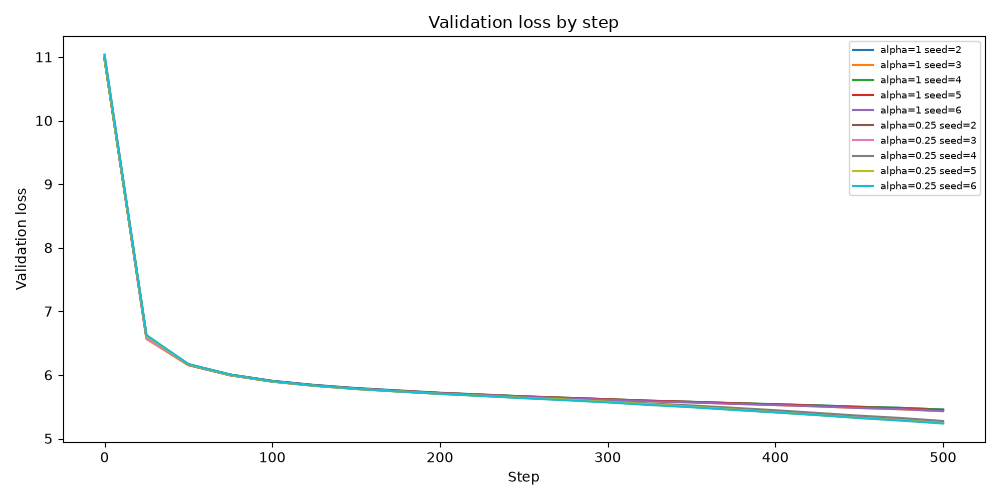

In [2]:
plt.figure(figsize=(10, 5))
for row in completed:
    plt.plot(*zip(*row['validation']), label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Step'); plt.ylabel('Validation loss'); plt.legend(fontsize='x-small')
plt.title('Validation loss by step')
plt.tight_layout()


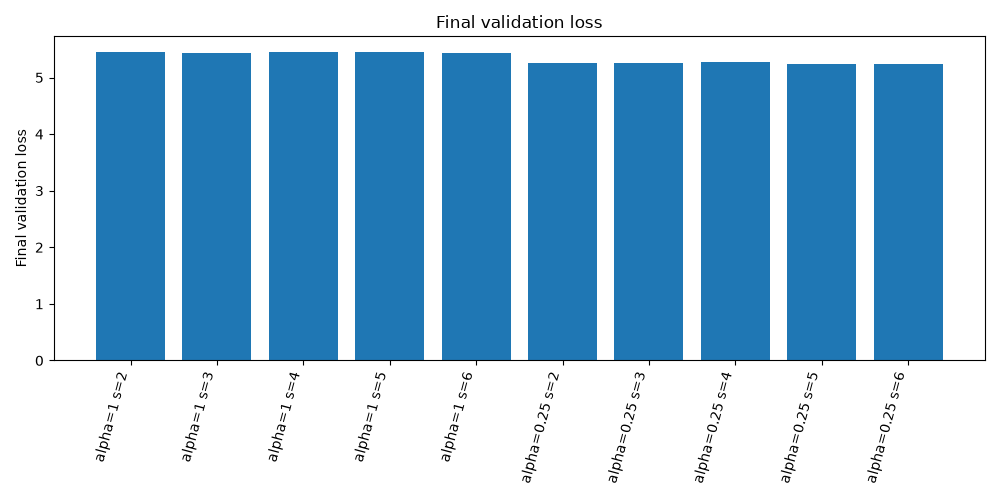

In [3]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(completed)), [row['final'] for row in completed])
plt.xticks(range(len(completed)), [f"{r['label']} s={r['seed']}" for r in completed], rotation=75, ha='right'); plt.ylabel('Final validation loss')
plt.title('Final validation loss')
plt.tight_layout()


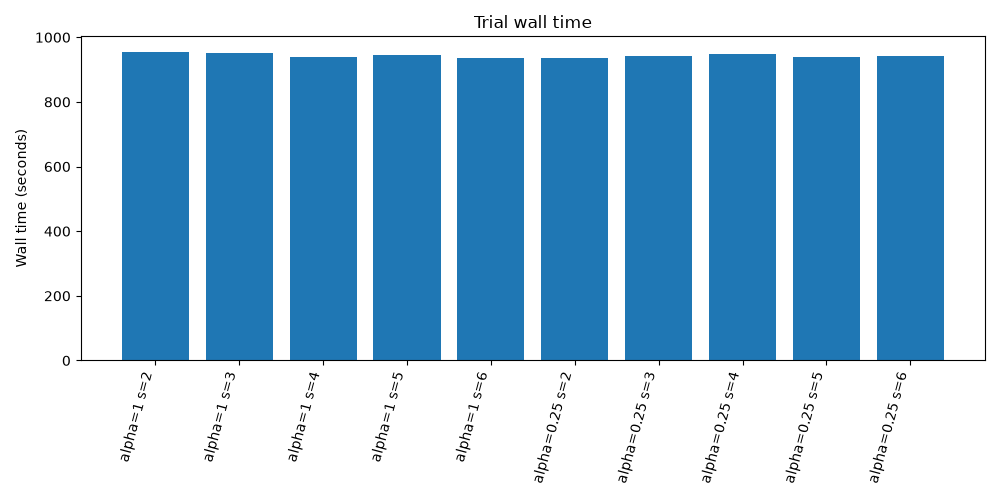

In [4]:
plt.figure(figsize=(10, 5))
plt.bar(range(len(data)), [row['seconds'] for row in data])
plt.xticks(range(len(data)), [f"{r['label']} s={r['seed']}" for r in data], rotation=75, ha='right'); plt.ylabel('Wall time (seconds)')
plt.title('Trial wall time')
plt.tight_layout()


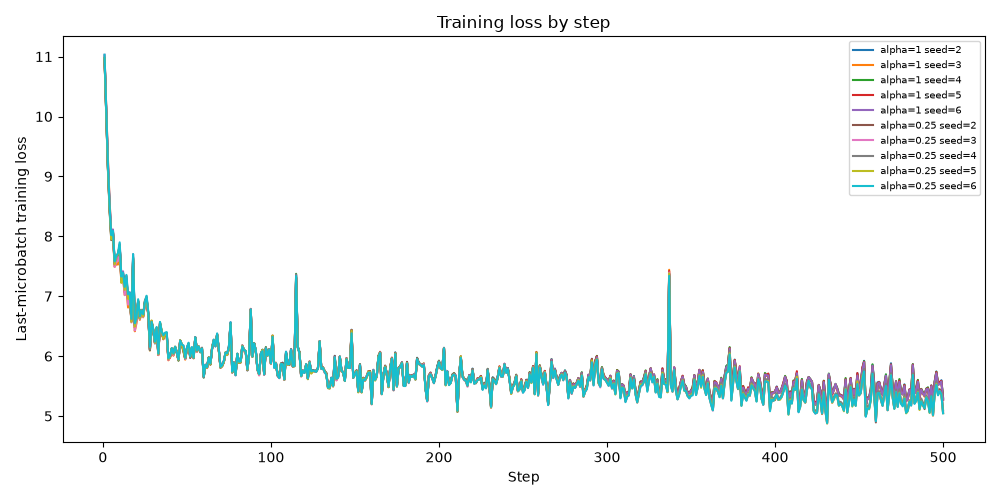

In [5]:
plt.figure(figsize=(10, 5))
for row in completed:
    if row['training']:
        plt.plot(*zip(*row['training']), label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Step'); plt.ylabel('Last-microbatch training loss'); plt.legend(fontsize='x-small')
plt.title('Training loss by step')
plt.tight_layout()


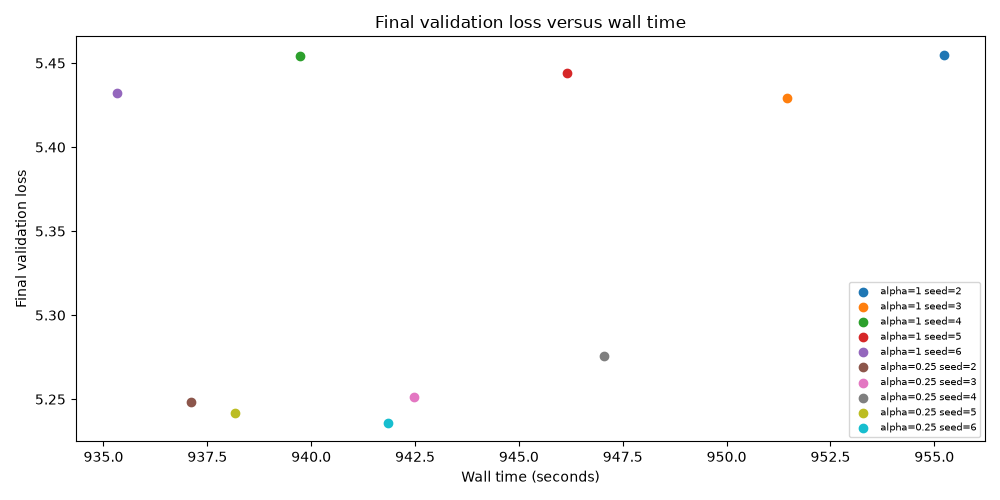

In [6]:
plt.figure(figsize=(10, 5))
for row in completed:
    plt.scatter(row['seconds'], row['final'], label=f"{row['label']} seed={row['seed']}")
plt.xlabel('Wall time (seconds)'); plt.ylabel('Final validation loss'); plt.legend(fontsize='x-small')
plt.title('Final validation loss versus wall time')
plt.tight_layout()
